In [ ]:
# ============================================================
# CELL 1 | SECTION 1: LIBRARY INSTALLATION
# ============================================================
# openpyxl reads modern Excel files (.xlsx); xlrd reads old ones (.xls)
!pip install -q openpyxl xlrd
print("✅ Libraries are ready.")

✅ Libraries are ready.


In [ ]:
# ============================================================
# CELL 2 | SECTION 2: IMPORTS AND SETTINGS
# ============================================================
import io
import os
import re
import zipfile
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display, Markdown

# ---- Display settings (only change how things look, not the data) ----
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ---- A list that collects every problem we discover (used in the final report) ----
issues = []

# ---- Small helper functions used by later cells ----
def show_title(text, level=3):
    """Prints a nice heading inside the notebook output."""
    display(Markdown(f"{'#' * level} {text}"))

# Detects column names that look like identifiers, e.g. "Row ID", "Postal Code"
ID_PATTERN = re.compile(r"(^|[^a-z])(id|code|postal|zip|index|no|number)([^a-z]|$)", re.I)

def is_id_like(column_name):
    return bool(ID_PATTERN.search(str(column_name)))

print("✅ Imports complete.")

✅ Imports complete.


In [ ]:
# ============================================================
# CELL 3 | SECTION 3: UPLOAD AND LOAD THE DATASET
# ============================================================
class DatasetLoadError(Exception):
    """Our own error type, used to show friendly messages."""
    pass

def read_csv_bytes(raw_bytes):
    """Reads a CSV. Tries several text encodings because many files
    downloaded from Kaggle are not plain UTF-8."""
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            data = pd.read_csv(io.BytesIO(raw_bytes), encoding=encoding, low_memory=False)
            # If everything landed in ONE column, the separator may not be a comma
            if data.shape[1] == 1:
                data = pd.read_csv(io.BytesIO(raw_bytes), encoding=encoding,
                                   sep=None, engine="python")
            return data, f"CSV (text encoding used: {encoding})"
        except UnicodeDecodeError:
            continue  # try the next encoding
    raise DatasetLoadError("The CSV file could not be decoded with any common text encoding.")

def read_excel_bytes(raw_bytes, extension):
    """Reads the FIRST sheet of an Excel file and reports all sheet names."""
    engine = "xlrd" if extension == ".xls" else "openpyxl"
    workbook = pd.ExcelFile(io.BytesIO(raw_bytes), engine=engine)
    sheets = workbook.sheet_names
    data = workbook.parse(sheets[0])
    note = f"Excel (sheet loaded: '{sheets[0]}')"
    if len(sheets) > 1:
        note += f" | Other sheets NOT loaded: {sheets[1:]}"
    return data, note

# ---- Step 1: ask the user to upload a file ----
print("📂 Please choose your dataset file (.csv, .xlsx, .xls) ...")
uploaded = files.upload()

# ---- Step 2: detect the file type and load it ----
try:
    if not uploaded:
        raise DatasetLoadError("No file was uploaded. Run this cell again and select a file.")

    file_name = list(uploaded.keys())[0]
    if len(uploaded) > 1:
        print(f"⚠️ You uploaded {len(uploaded)} files. Only the first one is used: {file_name}")

    raw_bytes = uploaded[file_name]
    extension = os.path.splitext(file_name)[1].lower()

    if extension == ".csv":
        df_raw, load_note = read_csv_bytes(raw_bytes)
    elif extension in (".xlsx", ".xlsm", ".xls"):
        df_raw, load_note = read_excel_bytes(raw_bytes, extension)
    else:
        raise DatasetLoadError(
            f"Unsupported file type '{extension}'. Please upload a .csv, .xlsx or .xls file.")

    if df_raw.empty or df_raw.shape[1] == 0:
        raise DatasetLoadError("The file was read but contains no data.")

except DatasetLoadError:
    raise
except pd.errors.EmptyDataError:
    raise DatasetLoadError("The file is empty. Please check that you uploaded the right file.") from None
except pd.errors.ParserError as e:
    raise DatasetLoadError(f"The file structure could not be parsed (possibly corrupted): {e}") from None
except zipfile.BadZipFile:
    raise DatasetLoadError("This Excel file looks corrupted or is not a real .xlsx file.") from None
except ImportError as e:
    raise DatasetLoadError(f"A required library is missing. Re-run Cell 1. Details: {e}") from None
except Exception as e:
    raise DatasetLoadError(f"Unexpected problem while loading the file: {type(e).__name__}: {e}") from None

# ---- Step 3: confirm success ----
print(f"\n✅ File loaded successfully: {file_name}")
print(f"   Format      : {load_note}")
print(f"   Rows        : {df_raw.shape[0]:,}")
print(f"   Columns     : {df_raw.shape[1]}")

# ---- Step 4: quick checks on the column names themselves ----
unnamed_cols = [c for c in df_raw.columns if str(c).startswith("Unnamed:")]
space_cols = [c for c in df_raw.columns if str(c) != str(c).strip()]
if unnamed_cols:
    issues.append(f"Columns without a proper header name: {unnamed_cols}")
if space_cols:
    issues.append(f"Column names with leading/trailing spaces: {space_cols}")

📂 Please choose your dataset file (.csv, .xlsx, .xls) ...


Saving Global Superstore.xls to Global Superstore.xls

✅ File loaded successfully: Global Superstore.xls
   Format      : Excel (sheet loaded: 'Orders') | Other sheets NOT loaded: ['Returns', 'People']
   Rows        : 51,290
   Columns     : 24


In [ ]:
# ============================================================
# CELL 4 | SECTION 4A: FIRST LOOK (HEAD, TAIL, SHAPE, COLUMNS, TYPES)
# ============================================================
show_title("4.1 First 10 rows")
display(df_raw.head(10))

show_title("4.2 Last 5 rows")
display(df_raw.tail(5))

show_title("4.3 Dataset size")
n_rows, n_cols = df_raw.shape
print(f"Number of rows    : {n_rows:,}")
print(f"Number of columns : {n_cols}")

show_title("4.4 Column names")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:>3}. {col}")

show_title("4.5 Data type of each column")
display(df_raw.dtypes.rename("Data Type").to_frame())

show_title("4.6 Dataset information (info)")
df_raw.info()

# ---- Group columns by type (reused in later cells) ----
num_cols = list(df_raw.select_dtypes(include="number").columns)
cat_cols = list(df_raw.select_dtypes(include=["object", "category", "bool"]).columns)

### 4.1 First 10 rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,"10,024.00",US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,NaN,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,NaN,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,Germany,NaN,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless","2,892.51",5,0.10,-96.54,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,Senegal,NaN,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed","2,832.96",8,0.00,311.52,903.04,Critical
5,22732,IN-2013-42360,2013-06-28,2013-07-01,Second Class,JM-15655,Jim Mitchum,Corporate,Sydney,New South Wales,Australia,NaN,APAC,Oceania,TEC-PH-10000030,Technology,Phones,"Samsung Smart Phone, with Caller ID","2,862.68",5,0.10,763.28,897.35,Critical
6,30570,IN-2011-81826,2011-11-07,2011-11-09,First Class,TS-21340,Toby Swindell,Consumer,Porirua,Wellington,New Zealand,NaN,APAC,Oceania,FUR-CH-10004050,Furniture,Chairs,"Novimex Executive Leather Armchair, Adjustable","1,822.08",4,0.00,564.84,894.77,Critical
7,31192,IN-2012-86369,2012-04-14,2012-04-18,Standard Class,MB-18085,Mick Brown,Consumer,Hamilton,Waikato,New Zealand,NaN,APAC,Oceania,FUR-TA-10002958,Furniture,Tables,"Chromcraft Conference Table, Fully Assembled","5,244.84",6,0.00,996.48,878.38,High
8,40155,CA-2014-135909,2014-10-14,2014-10-21,Standard Class,JW-15220,Jane Waco,Corporate,Sacramento,California,United States,"95,823.00",US,West,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,"5,083.96",5,0.20,"1,906.48",867.69,Low
9,40936,CA-2012-116638,2012-01-28,2012-01-31,Second Class,JH-15985,Joseph Holt,Consumer,Concord,North Carolina,United States,"28,027.00",US,South,FUR-TA-10000198,Furniture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"4,297.64",13,0.40,"-1,862.31",865.74,Critical


### 4.2 Last 5 rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
51285,29002,IN-2014-62366,2014-06-19,2014-06-19,Same Day,KE-16420,Katrina Edelman,Corporate,Kure,Hiroshima,Japan,NaN,APAC,North Asia,OFF-FA-10000746,Office Supplies,Fasteners,"Advantus Thumb Tacks, 12 Pack",65.10,5,0.00,4.50,0.01,Medium
51286,35398,US-2014-102288,2014-06-20,2014-06-24,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,Houston,Texas,United States,"77,095.00",US,Central,OFF-AP-10002906,Office Supplies,Appliances,Hoover Replacement Belt for Commercial Guardsm...,0.44,1,0.80,-1.11,0.01,Medium
51287,40470,US-2013-155768,2013-12-02,2013-12-02,Same Day,LB-16795,Laurel Beltran,Home Office,Oxnard,California,United States,"93,030.00",US,West,OFF-EN-10001219,Office Supplies,Envelopes,"#10- 4 1/8"" x 9 1/2"" Security-Tint Envelopes",22.92,3,0.00,11.23,0.01,High
51288,9596,MX-2012-140767,2012-02-18,2012-02-22,Standard Class,RB-19795,Ross Baird,Home Office,Valinhos,São Paulo,Brazil,NaN,LATAM,South,OFF-BI-10000806,Office Supplies,Binders,"Acco Index Tab, Economy",13.44,2,0.00,2.40,0.00,Medium
51289,6147,MX-2012-134460,2012-05-22,2012-05-26,Second Class,MC-18100,Mick Crebagga,Consumer,Tipitapa,Managua,Nicaragua,NaN,LATAM,Central,OFF-PA-10004155,Office Supplies,Paper,"Eaton Computer Printout Paper, 8.5 x 11",61.38,3,0.00,1.80,0.00,High


### 4.3 Dataset size

Number of rows    : 51,290
Number of columns : 24


... (2 outputs left out)

### 4.5 Data type of each column

,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
City,object
State,object


### 4.6 Dataset information (info)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  object        
 2   Order Date      51290 non-null  datetime64[ns]
 3   Ship Date       51290 non-null  datetime64[ns]
 4   Ship Mode       51290 non-null  object        
 5   Customer ID     51290 non-null  object        
 6   Customer Name   51290 non-null  object        
 7   Segment         51290 non-null  object        
 8   City            51290 non-null  object        
 9   State           51290 non-null  object        
 10  Country         51290 non-null  object        
 11  Postal Code     9994 non-null   float64       
 12  Market          51290 non-null  object        
 13  Region          51290 non-null  object        
 14  Product ID      51290 non-null  object        
 15  Ca

In [ ]:
# ============================================================
# CELL 8 | SECTION 5A: DATA TYPE INVESTIGATION
# ============================================================
# Looks for: dates stored as text, numbers stored as text,
# identifier columns stored as numbers, etc.
# These are SUGGESTIONS only. Nothing is changed.

DATE_NAME_HINT = re.compile(r"date|time", re.I)
DATE_VALUE_PATTERN = r"\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}"

def try_parse(series, dayfirst):
    """Tries to convert text to dates. Failures become NaT (no crash)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return pd.to_datetime(series, errors="coerce", dayfirst=dayfirst, format="mixed")

already_datetime = list(df_raw.select_dtypes(include=["datetime64"]).columns)
date_candidates = {}   # column -> details about how it parsed
type_findings = []     # rows for the findings table

# ---- Text columns: do they look like dates or numbers? ----
for col in df_raw.select_dtypes(include=["object"]).columns:
    values = df_raw[col].dropna().astype(str).str.strip()
    values = values[values != ""]
    if values.empty:
        continue
    sample = values.sample(min(len(values), 5000), random_state=42)

    looks_like_date = (sample.str.contains(DATE_VALUE_PATTERN, regex=True).mean() >= 0.8
                       or bool(DATE_NAME_HINT.search(col)))
    if looks_like_date:
        rates = {flag: try_parse(sample, flag).notna().mean() for flag in (False, True)}
        best = max(rates, key=rates.get)
        if rates[best] >= 0.90:
            date_candidates[col] = {"dayfirst": best, "month_first_rate": rates[False],
                                    "day_first_rate": rates[True]}
            type_findings.append([col, "text (object)", "Looks like a DATE",
                                  "Convert to datetime in Stage 2"])
            issues.append(f"'{col}' is stored as text but can be read as dates.")
            continue

    # Numbers hiding inside text (e.g. "1,200" or "$50")?
    if not is_id_like(col):
        cleaned = sample.str.replace(r"[,\s$€£%]", "", regex=True)
        numeric_rate = pd.to_numeric(cleaned, errors="coerce").notna().mean()
        if numeric_rate >= 0.90:
            type_findings.append([col, "text (object)", f"{numeric_rate:.0%} of values look numeric",
                                  "Convert to numeric in Stage 2"])
            issues.append(f"'{col}' is stored as text but looks numeric.")

# ---- Numeric columns: are they really identifiers or whole numbers? ----
for col in num_cols:
    if is_id_like(col):
        type_findings.append([col, str(df_raw[col].dtype), "Numeric, but name suggests an identifier/code",
                              "Treat as text/category, not for calculations"])
        issues.append(f"'{col}' is numeric but looks like an identifier/code (should not be averaged or summed).")
    elif pd.api.types.is_float_dtype(df_raw[col]):
        non_null = df_raw[col].dropna()
        if len(non_null) > 0 and (non_null % 1 == 0).all():
            type_findings.append([col, str(df_raw[col].dtype), "Decimal type but all values are whole numbers",
                                  "Could be converted to integer (optional)"])

show_title("5.1 Data type findings")
if type_findings:
    display(pd.DataFrame(type_findings,
            columns=["Column", "Current Type", "Finding", "Suggested Action"]))
else:
    print("✅ No obvious data type problems detected.")
if already_datetime:
    print(f"\nColumns already stored as datetime: {already_datetime}")

### 5.1 Data type findings

,Column,Current Type,Finding,Suggested Action
0,Row ID,int64,"Numeric, but name suggests an identifier/code","Treat as text/category, not for calculations"
1,Postal Code,float64,"Numeric, but name suggests an identifier/code","Treat as text/category, not for calculations"



Columns already stored as datetime: ['Order Date', 'Ship Date']


In [ ]:
# ============================================================
# CELL 9 | SECTION 5B: DATE COLUMN INVESTIGATION
# ============================================================
# Converts date columns ONLY in temporary variables to test them.
# df_raw stays untouched.

date_cols_all = already_datetime + list(date_candidates)
parsed_store = {}   # temporary converted copies

if not date_cols_all:
    print("No date-like columns were detected.")
else:
    rows = []
    fmt = lambda t: t.strftime("%Y-%m-%d") if pd.notna(t) else "N/A"

    for col in date_cols_all:
        raw = df_raw[col]
        if col in already_datetime:
            parsed, mask, ambiguous = raw, raw.notna(), 0.0
            mf_rate = df_rate = 1.0
        else:
            text = raw.where(raw.notna()).astype(str).str.strip()
            mask = raw.notna() & (text != "")
            dfirst = date_candidates[col]["dayfirst"]
            parsed = try_parse(text.where(mask), dfirst)
            alt = try_parse(text.where(mask), not dfirst)
            both = parsed.notna() & alt.notna()
            ambiguous = (parsed[both] != alt[both]).mean() * 100 if both.any() else 0.0
            mf_rate = date_candidates[col]["month_first_rate"]
            df_rate = date_candidates[col]["day_first_rate"]
        parsed_store[col] = parsed

        failed = int((mask & parsed.isna()).sum())
        if failed > 0:
            issues.append(f"'{col}': {failed:,} non-empty values could not be converted to dates.")
        if ambiguous > 0:
            issues.append(f"'{col}': {ambiguous:.1f}% of dates are ambiguous between day-first and "
                          f"month-first. The date format must be confirmed before Stage 2.")

        rows.append({
            "Column": col,
            "Non-empty Values": int(mask.sum()),
            "Failed to Convert": failed,
            "Month-first Success %": round(mf_rate * 100, 1),
            "Day-first Success %": round(df_rate * 100, 1),
            "Day/Month Ambiguous %": round(ambiguous, 1),
            "Earliest": fmt(parsed.min()),
            "Latest": fmt(parsed.max()),
            "Example Raw Values": list(raw.dropna().astype(str).head(3)),
        })

    show_title("5.2 Date conversion test")
    display(pd.DataFrame(rows))
    print("ℹ️ 'Ambiguous' means a value such as 03/04/2012 could be 3 April or 4 March.")
    print("   Compare the two Success % columns, and the Earliest/Latest dates, to judge the correct format.")

    # ---- Compare date columns with each other ----
    if len(parsed_store) >= 2:
        show_title("5.3 Date columns compared with each other")
        pair_rows = []
        for a, b in combinations(parsed_store, 2):
            both = parsed_store[a].notna() & parsed_store[b].notna()
            pair_rows.append({
                "Column A": a, "Column B": b,
                "Rows A later than B": int((parsed_store[a][both] > parsed_store[b][both]).sum()),
                "Rows A earlier than B": int((parsed_store[a][both] < parsed_store[b][both]).sum()),
                "Rows equal": int((parsed_store[a][both] == parsed_store[b][both]).sum()),
            })
        display(pd.DataFrame(pair_rows))
        print("ℹ️ Use this to check logic, e.g. a delivery date should not come before an order date.")

### 5.2 Date conversion test

,Column,Non-empty Values,Failed to Convert,Month-first Success %,Day-first Success %,Day/Month Ambiguous %,Earliest,Latest,Example Raw Values
0,Order Date,51290,0,100.00,100.00,0.00,2011-01-01,2014-12-31,"[2012-07-31, 2013-02-05, 2013-10-17]"
1,Ship Date,51290,0,100.00,100.00,0.00,2011-01-03,2015-01-07,"[2012-07-31, 2013-02-07, 2013-10-18]"


ℹ️ 'Ambiguous' means a value such as 03/04/2012 could be 3 April or 4 March.
   Compare the two Success % columns, and the Earliest/Latest dates, to judge the correct format.


### 5.3 Date columns compared with each other

,Column A,Column B,Rows A later than B,Rows A earlier than B,Rows equal
0,Order Date,Ship Date,0,48690,2600


ℹ️ Use this to check logic, e.g. a delivery date should not come before an order date.


### 5.4 Potential outliers (IQR method)

,Min,Q1,Median,Q3,Max,Lower Bound,Upper Bound,Below Lower,Above Upper,Outlier %
Column,,,,,,,,,,
Sales,0.44,30.76,85.05,251.05,"22,638.48",-299.68,581.50,0,5655,11.03
Quantity,1.00,2.00,3.00,5.00,14.00,-2.50,9.50,0,877,1.71
Discount,0.00,0.00,0.00,0.20,0.85,-0.30,0.50,0,4172,8.13
Profit,"-6,599.98",0.00,9.24,36.81,"8,399.98",-55.22,92.03,3526,6229,19.02
Shipping Cost,0.00,2.61,7.79,24.45,933.57,-30.15,57.21,0,5909,11.52


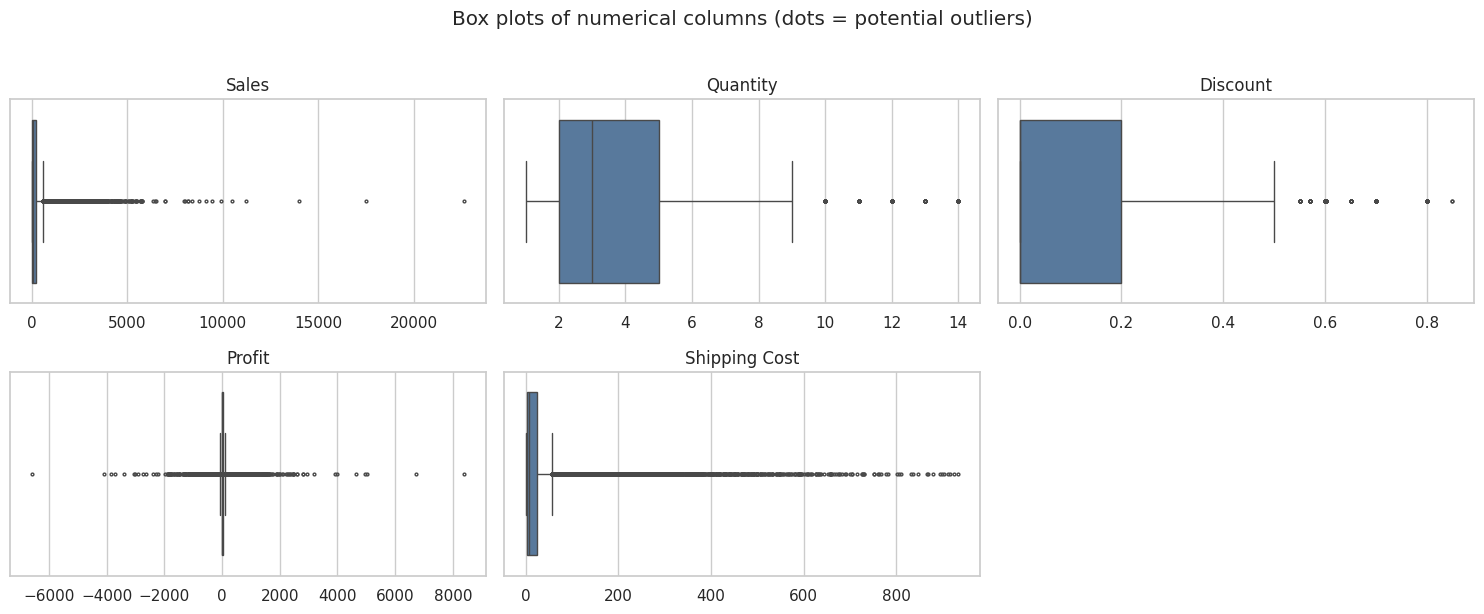

In [ ]:
# ============================================================
# CELL 10 | SECTION 5C: OUTLIER DETECTION (NO DELETION)
# ============================================================
# Method: IQR rule. A value is a *potential* outlier if it lies
# more than 1.5 × IQR below Q1 or above Q3.
# Business data is often skewed, so outliers may be genuine.

outlier_cols = [c for c in num_cols
                if not is_id_like(c) and df_raw[c].nunique(dropna=True) > 1]

outlier_rows = []
for col in outlier_cols:
    s = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_low, n_high = int((s < low).sum()), int((s > high).sum())
    outlier_rows.append({
        "Column": col, "Min": s.min(), "Q1": q1, "Median": s.median(), "Q3": q3, "Max": s.max(),
        "Lower Bound": low, "Upper Bound": high,
        "Below Lower": n_low, "Above Upper": n_high,
        "Outlier %": round((n_low + n_high) / len(s) * 100, 2),
    })

show_title("5.4 Potential outliers (IQR method)")
if outlier_rows:
    outlier_table = pd.DataFrame(outlier_rows).set_index("Column")
    display(outlier_table)

    flagged = outlier_table[(outlier_table["Below Lower"] + outlier_table["Above Upper"]) > 0]
    if len(flagged):
        summary = ", ".join(f"{c} ({p}%)" for c, p in flagged["Outlier %"].items())
        issues.append("Potential outliers flagged (kept, not removed): " + summary)

    # ---- Box plots ----
    n = len(outlier_cols)
    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, outlier_cols):
        sns.boxplot(x=df_raw[col].replace([np.inf, -np.inf], np.nan).dropna(),
                    ax=ax, color="#4C78A8", fliersize=2)
        ax.set_title(col)
        ax.set_xlabel("")
    for ax in axes[n:]:
        ax.axis("off")
    plt.suptitle("Box plots of numerical columns (dots = potential outliers)", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable numerical columns for outlier analysis.")

# ---- Helper: look at the most extreme rows of any column ----
def show_extremes(column, n=5):
    """Example: show_extremes('YourColumnName')  (use a real column name)"""
    print(f"Highest {n} values in '{column}':")
    display(df_raw.nlargest(n, column))
    print(f"Lowest {n} values in '{column}':")
    display(df_raw.nsmallest(n, column))

### 5.5 Missing values

Total missing cells        : 41,296
Rows with at least 1 gap   : 41,296 (80.51% of rows)


,Missing Values,Missing %
Postal Code,41296,80.51


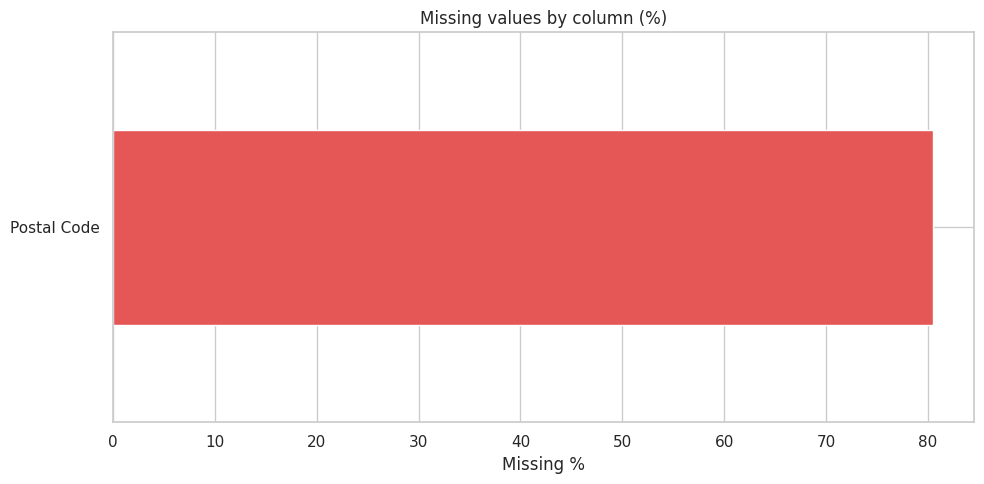

### 5.6 Hidden missing values and extra spaces in text columns

,Column,Blank/Placeholder Values,Values with Extra Spaces
0,Product Name,0,16


### 5.7 Duplicate records

Exact duplicate rows            : 0
Rows involved in any duplication: 0


### 5.8 Identifier-like columns: uniqueness check

,Unique Values,Total Rows,All Unique?
Row ID,51290,51290,True
Order ID,25035,51290,False
Customer ID,1590,51290,False
Postal Code,631,51290,False
Product ID,10292,51290,False


ℹ️ An ID repeating across rows is not necessarily wrong (e.g. one order with several items).


In [ ]:
# ============================================================
# CELL 11 | SECTION 5D: MISSING VALUES AND DUPLICATES (DEEPER CHECK)
# ============================================================
show_title("5.5 Missing values")
total_missing = int(df_raw.isna().sum().sum())
rows_with_missing = int(df_raw.isna().any(axis=1).sum())
print(f"Total missing cells        : {total_missing:,}")
print(f"Rows with at least 1 gap   : {rows_with_missing:,} "
      f"({rows_with_missing / len(df_raw) * 100:.2f}% of rows)")

# ---- Define missing_table to resolve the NameError ----
missing_counts = df_raw.isna().sum()
missing_pct = (missing_counts / len(df_raw)) * 100
missing_table = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing %": missing_pct
})

cols_missing = missing_table[missing_table["Missing Values"] > 0]
if len(cols_missing):
    display(cols_missing.sort_values("Missing Values", ascending=False))
    issues.append("Missing values found in: " +
                  ", ".join(f"{c} ({int(r['Missing Values']):,})" for c, r in cols_missing.iterrows()))
    ax = cols_missing["Missing %"].sort_values().plot(kind="barh", color="#E45756")
    ax.set_title("Missing values by column (%)")
    ax.set_xlabel("Missing %")
    plt.tight_layout()
    plt.show()
else:
    print("✅ No standard missing values (NaN) found.")

# ---- Hidden missing values: blanks and placeholder text ----
show_title("5.6 Hidden missing values and extra spaces in text columns")
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "unknown", "-", "--", "?", "missing", "undefined"}
hidden_rows = []
for col in df_raw.select_dtypes(include=["object"]).columns:
    text = df_raw[col].dropna().astype(str)
    stripped = text.str.strip()
    n_placeholder = int(stripped.str.lower().isin(PLACEHOLDERS).sum())
    n_spaces = int((text != stripped).sum())
    if n_placeholder or n_spaces:
        hidden_rows.append({"Column": col,
                            "Blank/Placeholder Values": n_placeholder,
                            "Values with Extra Spaces": n_spaces})
if hidden_rows:
    display(pd.DataFrame(hidden_rows))
    issues.append("Text columns with blank/placeholder values or extra spaces: " +
                  ", ".join(r["Column"] for r in hidden_rows))
else:
    print("✅ No hidden placeholders or extra spaces found.")

# ---- Duplicates ----
show_title("5.7 Duplicate records")
dup_rows = int(df_raw.duplicated().sum())
dup_involved = int(df_raw.duplicated(keep=False).sum())
print(f"Exact duplicate rows            : {dup_rows:,}")
print(f"Rows involved in any duplication: {dup_involved:,}")
if dup_rows:
    issues.append(f"{dup_rows:,} exact duplicate rows found.")
    display(df_raw[df_raw.duplicated(keep=False)].head(10))

# ---- Identifier-like columns ----
id_cols = [c for c in df_raw.columns if is_id_like(c)]
if id_cols:
    show_title("5.8 Identifier-like columns: uniqueness check")
    display(pd.DataFrame({
        "Unique Values": [df_raw[c].nunique() for c in id_cols],
        "Total Rows": len(df_raw),
        "All Unique?": [df_raw[c].is_unique for c in id_cols],
    }, index=id_cols))
    print("ℹ️ An ID repeating across rows is not necessarily wrong (e.g. one order with several items).")

In [ ]:
# ============================================================
# CELL 12 | SECTION 5E: UNEXPECTED VALUES CHECK
# ============================================================
# NOTE: Negative profit is NOT treated as an error. It can be a real loss.

show_title("5.9 Negative / zero / infinite values in numerical columns")
check_rows = []
for col in num_cols:
    s = df_raw[col]
    check_rows.append({
        "Column": col, "Negative": int((s < 0).sum()), "Zero": int((s == 0).sum()),
        "Infinite": int(np.isinf(s).sum()), "Min": s.min(), "Max": s.max(),
    })
display(pd.DataFrame(check_rows).set_index("Column"))

# ---- Rules applied ONLY if a matching column name exists ----
show_title("5.10 Business-rule checks (based on column names found)")
rule_messages = []
for col in num_cols:
    name = col.lower()
    s = df_raw[col].dropna()
    if "profit" in name:
        neg = s[s < 0]
        rule_messages.append(
            f"ℹ️ '{col}': {len(neg):,} negative rows ({len(neg) / max(len(s), 1) * 100:.2f}%), "
            f"total of negatives = {neg.sum():,.2f}. These are KEPT: they may be genuine business losses.")
    elif "discount" in name:
        bad = int(((s < 0) | (s > 1)).sum())
        rule_messages.append(f"'{col}': {bad:,} values outside the 0 to 1 range (max = {s.max():,.2f}). "
                             f"If the maximum is above 1, discounts may be stored as percentages.")
        if bad:
            issues.append(f"'{col}' has {bad:,} values outside 0 to 1; confirm the discount scale.")
    elif "quantity" in name:
        non_pos = int((s <= 0).sum())
        non_int = int((s % 1 != 0).sum())
        rule_messages.append(f"'{col}': {non_pos:,} values ≤ 0 and {non_int:,} non-whole numbers.")
        if non_pos or non_int:
            issues.append(f"'{col}' has unexpected values (≤0 or fractional).")
    elif any(k in name for k in ("sales", "shipping", "cost", "price", "amount", "revenue")):
        neg = int((s < 0).sum())
        rule_messages.append(f"'{col}': {neg:,} negative values.")
        if neg:
            issues.append(f"'{col}' has {neg:,} negative values (not normally expected).")
if rule_messages:
    for m in rule_messages:
        print(m)
else:
    print("No columns matched the name-based business rules.")

# ---- Constant columns ----
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) == 1]
show_title("5.11 Columns with only one value")
print(constant_cols if constant_cols else "✅ None")
if constant_cols:
    issues.append(f"Columns containing a single constant value: {constant_cols}")

# ---- Inconsistent labels (e.g. 'Paper' vs 'paper ') ----
show_title("5.12 Inconsistent text labels")
label_problems = []
for col in df_raw.select_dtypes(include=["object"]).columns:
    s = df_raw[col].dropna().astype(str)
    if s.nunique() <= 100:
        normalised = s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
        if normalised.nunique() < s.nunique():
            label_problems.append(col)
print(label_problems if label_problems else "✅ No case/spacing label inconsistencies found.")
if label_problems:
    issues.append(f"Labels that differ only by capitalisation/spacing in: {label_problems}")

### 5.9 Negative / zero / infinite values in numerical columns

,Negative,Zero,Infinite,Min,Max
Column,,,,,
Row ID,0,0,0,1.00,"51,290.00"
Postal Code,0,0,0,"1,040.00","99,301.00"
Sales,0,0,0,0.44,"22,638.48"
Quantity,0,0,0,1.00,14.00
Discount,0,29009,0,0.00,0.85
Profit,12544,668,0,"-6,599.98","8,399.98"
Shipping Cost,0,0,0,0.00,933.57


### 5.10 Business-rule checks (based on column names found)

'Sales': 0 negative values.
'Quantity': 0 values ≤ 0 and 0 non-whole numbers.
'Discount': 0 values outside the 0 to 1 range (max = 0.85). If the maximum is above 1, discounts may be stored as percentages.
ℹ️ 'Profit': 12,544 negative rows (24.46%), total of negatives = -920,646.16. These are KEPT: they may be genuine business losses.
'Shipping Cost': 0 negative values.


### 5.11 Columns with only one value

✅ None


### 5.12 Inconsistent text labels

✅ No case/spacing label inconsistencies found.


In [ ]:
# ============================================================
# CELL 13 | SECTION 6: DATASET DOCUMENTATION
# ============================================================
def classify(col):
    if col in already_datetime or col in date_candidates:
        return "Date-related"
    if col in num_cols:
        return "Numeric (identifier-like)" if is_id_like(col) else "Numeric"
    if col in cat_cols:
        return "Categorical (identifier-like)" if is_id_like(col) else "Categorical"
    return "Other"

variable_summary = pd.DataFrame({
    "Variable Type": [classify(c) for c in df_raw.columns],
    "Data Type": df_raw.dtypes.astype(str).values,
    "Unique Values": df_raw.nunique(dropna=True).values,
    "Missing Values": df_raw.isna().sum().values,
}, index=df_raw.columns)

show_title("6.1 Dataset size")
mem_mb = df_raw.memory_usage(deep=True).sum() / 1024**2
print(f"File name   : {file_name}")
print(f"Rows        : {df_raw.shape[0]:,}")
print(f"Columns     : {df_raw.shape[1]}")
print(f"Memory used : {mem_mb:,.2f} MB")

show_title("6.2 All variables and their types")
display(variable_summary)

show_title("6.3 Variables grouped by type")
for vtype in variable_summary["Variable Type"].unique():
    members = list(variable_summary.index[variable_summary["Variable Type"] == vtype])
    print(f"• {vtype} ({len(members)}): {members}")

# ---- Keyword-based suggestions for each analysis area ----
def find_columns(keywords):
    return [c for c in df_raw.columns if any(k in c.lower() for k in keywords)]

date_cols_doc = already_datetime + list(date_candidates)

analysis_groups = {
    "Sales analysis": find_columns(["sales", "revenue", "quantity", "order", "product",
                                    "category", "price", "item"]) + date_cols_doc,
    "Customer analysis": find_columns(["customer", "segment", "client"]),
    "Geographical analysis": find_columns(["country", "state", "city", "region", "market",
                                           "postal", "zip", "province", "location",
                                           "latitude", "longitude"]),
    "Profit and discount analysis": find_columns(["profit", "discount", "margin", "shipping", "cost"]),
}

show_title("6.4 Suggested variables for each analysis area")
for area, cols in analysis_groups.items():
    unique_cols = list(dict.fromkeys(cols))   # remove duplicates, keep order
    print(f"• {area}:")
    print(f"    {unique_cols if unique_cols else 'No obvious match by column name'}")
print("\nℹ️ These suggestions come from column-name keywords. Please check them against the data.")

### 6.1 Dataset size

File name   : Global Superstore.xls
Rows        : 51,290
Columns     : 24
Memory used : 47.75 MB


### 6.2 All variables and their types

,Variable Type,Data Type,Unique Values,Missing Values
Row ID,Numeric (identifier-like),int64,51290,0
Order ID,Categorical (identifier-like),object,25035,0
Order Date,Date-related,datetime64[ns],1430,0
Ship Date,Date-related,datetime64[ns],1464,0
Ship Mode,Categorical,object,4,0
Customer ID,Categorical (identifier-like),object,1590,0
Customer Name,Categorical,object,795,0
Segment,Categorical,object,3,0
City,Categorical,object,3636,0
State,Categorical,object,1094,0


### 6.3 Variables grouped by type

• Numeric (identifier-like) (2): ['Row ID', 'Postal Code']
• Categorical (identifier-like) (3): ['Order ID', 'Customer ID', 'Product ID']
• Date-related (2): ['Order Date', 'Ship Date']
• Categorical (12): ['Ship Mode', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Market', 'Region', 'Category', 'Sub-Category', 'Product Name', 'Order Priority']
• Numeric (5): ['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost']


### 6.4 Suggested variables for each analysis area

• Sales analysis:
    ['Order ID', 'Order Date', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Order Priority', 'Ship Date']
• Customer analysis:
    ['Customer ID', 'Customer Name', 'Segment']
• Geographical analysis:
    ['City', 'State', 'Country', 'Postal Code', 'Market', 'Region']
• Profit and discount analysis:
    ['Discount', 'Profit', 'Shipping Cost']

ℹ️ These suggestions come from column-name keywords. Please check them against the data.


In [ ]:
# ============================================================
# CELL 14 | SECTION 7: FINAL STAGE 1 REPORT
# ============================================================
print("=" * 70)
print("STAGE 1 REPORT: ACTUAL DATASET STRUCTURE AND ISSUES")
print("=" * 70)

print(f"\nFile            : {file_name}   [{load_note}]")
print(f"Size            : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Duplicate rows  : {int(df_raw.duplicated().sum()):,}")
print(f"Missing cells   : {int(df_raw.isna().sum().sum()):,}")

print("\nVariable types:")
for vtype, count in variable_summary["Variable Type"].value_counts().items():
    print(f"  - {vtype}: {count}")

print("\nColumns:")
for vtype in variable_summary["Variable Type"].unique():
    members = list(variable_summary.index[variable_summary["Variable Type"] == vtype])
    print(f"  [{vtype}] {members}")

print(f"\nISSUES DISCOVERED ({len(issues)}):")
if issues:
    for i, issue in enumerate(issues, start=1):
        print(f"  {i}. {issue}")
else:
    print("  No issues detected.")

print("\nNOTES:")
print("  - The original dataset (df_raw) has NOT been modified.")
print("  - Outliers and negative values were flagged only, never removed.")
print("  - Stage 2 (data cleaning) has NOT been started.")
print("=" * 70)

STAGE 1 REPORT: ACTUAL DATASET STRUCTURE AND ISSUES

File            : Global Superstore.xls   [Excel (sheet loaded: 'Orders') | Other sheets NOT loaded: ['Returns', 'People']]
Size            : 51,290 rows × 24 columns
Duplicate rows  : 0
Missing cells   : 41,296

Variable types:
  - Categorical: 12
  - Numeric: 5
  - Categorical (identifier-like): 3
  - Numeric (identifier-like): 2
  - Date-related: 2

Columns:
  [Numeric (identifier-like)] ['Row ID', 'Postal Code']
  [Categorical (identifier-like)] ['Order ID', 'Customer ID', 'Product ID']
  [Date-related] ['Order Date', 'Ship Date']
  [Categorical] ['Ship Mode', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Market', 'Region', 'Category', 'Sub-Category', 'Product Name', 'Order Priority']
  [Numeric] ['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost']

ISSUES DISCOVERED (5):
  1. 'Row ID' is numeric but looks like an identifier/code (should not be averaged or summed).
  2. 'Postal Code' is numeric but looks like a

In [ ]:
# ============================================================
# STAGE 1 FOLLOW-UP CHECKS (read-only, nothing is modified)
# ============================================================

# --- Check A: Product Name issue (blank / placeholder / extra spaces) ---
col = "Product Name"
text = df_raw[col].dropna().astype(str)
stripped = text.str.strip()
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "unknown", "-", "--", "?", "missing", "undefined"}

is_placeholder = stripped.str.lower().isin(PLACEHOLDERS)
has_spaces = text != stripped
print(f"Placeholder/blank values : {int(is_placeholder.sum()):,}")
print(f"Values with extra spaces : {int(has_spaces.sum()):,}")
print("\nExamples of placeholder values:")
print(text[is_placeholder].value_counts().head(10))
print("\nExamples with extra spaces:")
print(text[has_spaces].head(5).tolist())

# --- Check B: Which countries have missing Postal Codes? ---
missing_pc = df_raw[df_raw["Postal Code"].isna()]
by_country = pd.DataFrame({
    "Rows": df_raw.groupby("Country").size(),
    "Missing Postal": missing_pc.groupby("Country").size(),
}).fillna(0).astype(int)
by_country["% Missing"] = (by_country["Missing Postal"] / by_country["Rows"] * 100).round(1)
print("\nCountries with at least one missing postal code:", int((by_country["Missing Postal"] > 0).sum()),
      "of", len(by_country))
print("\nCountries with postal codes present in at least some rows:")
display(by_country[by_country["% Missing"] < 100].sort_values("Rows", ascending=False))

# --- Check C: Date logic (Ship Date should not be before Order Date) ---
bad_ship = df_raw[df_raw["Ship Date"] < df_raw["Order Date"]]
print(f"\nRows where Ship Date is before Order Date: {len(bad_ship):,}")
print(f"Order Date range : {df_raw['Order Date'].min().date()} to {df_raw['Order Date'].max().date()}")
print(f"Ship Date range  : {df_raw['Ship Date'].min().date()} to {df_raw['Ship Date'].max().date()}")

# --- Check D: Is Row ID unique, and how are Order IDs repeated? ---
print(f"\nRow ID unique?          : {df_raw['Row ID'].is_unique}")
print(f"Unique Order IDs        : {df_raw['Order ID'].nunique():,} (rows: {len(df_raw):,})")

# --- Check E: Date ambiguity warning from Cell 9 ---
print("\nPlease also paste the 'Day/Month Ambiguous %' values from Cell 9's table.")

Placeholder/blank values : 0
Values with extra spaces : 16

Examples of placeholder values:
Series([], Name: count, dtype: int64)

Examples with extra spaces:
['Iceberg Mobile Mega Data/Printer Cart ', 'Iceberg Mobile Mega Data/Printer Cart ', 'Iceberg Mobile Mega Data/Printer Cart ', 'Iceberg Mobile Mega Data/Printer Cart ', 'Iceberg Mobile Mega Data/Printer Cart ']

Countries with at least one missing postal code: 146 of 147

Countries with postal codes present in at least some rows:


,Rows,Missing Postal,% Missing
Country,,,
United States,9994,0,0.00



Rows where Ship Date is before Order Date: 0
Order Date range : 2011-01-01 to 2014-12-31
Ship Date range  : 2011-01-03 to 2015-01-07

Row ID unique?          : True
Unique Order IDs        : 25,035 (rows: 51,290)

Please also paste the 'Day/Month Ambiguous %' values from Cell 9's table.


In [ ]:
# ============================================================
# CELL 15 | SECTION 8A: LOAD RETURNS AND PEOPLE SHEETS
# ============================================================
engine = "xlrd" if extension == ".xls" else "openpyxl"
book = pd.ExcelFile(io.BytesIO(raw_bytes), engine=engine)
print("Sheets in the file:", book.sheet_names)

def load_sheet(name):
    if name in book.sheet_names:
        return book.parse(name)
    print(f"⚠️ Sheet '{name}' was not found.")
    return None

df_returns_raw = load_sheet("Returns")
df_people_raw = load_sheet("People")

for label, sheet in [("Returns", df_returns_raw), ("People", df_people_raw)]:
    if sheet is None:
        continue
    show_title(f"{label} sheet")
    print(f"Rows: {sheet.shape[0]:,} | Columns: {sheet.shape[1]}")
    print("Columns:", list(sheet.columns))
    display(sheet.head(5))
    print("Missing values per column:")
    print(sheet.isna().sum().to_string())
    print(f"Duplicate rows: {int(sheet.duplicated().sum()):,}")
    for col in sheet.columns:
        if sheet[col].nunique() <= 15:
            print(f"Values in '{col}': {sorted(sheet[col].dropna().unique().tolist())}")

Sheets in the file: ['Orders', 'Returns', 'People']


### Returns sheet

Rows: 1,173 | Columns: 3
Columns: ['Returned', 'Order ID', 'Market']


,Returned,Order ID,Market
0,Yes,MX-2013-168137,LATAM
1,Yes,US-2011-165316,LATAM
2,Yes,ES-2013-1525878,EU
3,Yes,CA-2013-118311,United States
4,Yes,ES-2011-1276768,EU


Missing values per column:
Returned    0
Order ID    0
Market      0
Duplicate rows: 0
Values in 'Returned': ['Yes']
Values in 'Market': ['APAC', 'EU', 'LATAM', 'United States']


### People sheet

Rows: 13 | Columns: 2
Columns: ['Person', 'Region']


,Person,Region
0,Anna Andreadi,Central
1,Chuck Magee,South
2,Kelly Williams,East
3,Matt Collister,West
4,Deborah Brumfield,Africa


Missing values per column:
Person    0
Region    0
Duplicate rows: 0
Values in 'Person': ['Alejandro Ballentine', 'Anna Andreadi', 'Anthony Jacobs', 'Chuck Magee', 'Deborah Brumfield', 'Giulietta Dortch', 'Jack Lebron', 'Kelly Williams', 'Larry Hughes', 'Matt Collister', 'Nicole Hansen', 'Nora Preis', 'Shirley Daniels']
Values in 'Region': ['AMEA', 'Africa', 'Canada', 'Caribbean', 'Central', 'Central Asia', 'East', 'North', 'North Asia', 'Oceania', 'South', 'Southeast Asia', 'West']


In [ ]:
# ============================================================
# CELL 16 | SECTION 9: BASIC CLEANING ON A COPY
# ============================================================
df_clean = df_raw.copy()          # df_raw stays untouched

# 1. Trim leading/trailing spaces in all text columns
text_columns = df_clean.select_dtypes(include="object").columns
unique_products_before = df_clean["Product Name"].nunique()
for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip().astype("object")
unique_products_after = df_clean["Product Name"].nunique()

print(f"Text columns trimmed: {len(text_columns)}")
print(f"Unique Product Names: {unique_products_before:,} before, {unique_products_after:,} after trimming")
if unique_products_before != unique_products_after:
    print("ℹ️ Trimming merged product names that differed only by spaces.")

# 2. Remove Postal Code (it only exists for the United States)
df_clean = df_clean.drop(columns=["Postal Code"])
print("\n✅ 'Postal Code' removed from df_clean.")

# 3. Confirm key columns have the right types
print("\nDate columns are datetime:",
      pd.api.types.is_datetime64_any_dtype(df_clean["Order Date"]),
      pd.api.types.is_datetime64_any_dtype(df_clean["Ship Date"]))
print(f"Remaining missing values in df_clean: {int(df_clean.isna().sum().sum()):,}")
print(f"Shape now: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Text columns trimmed: 15
Unique Product Names: 3,788 before, 3,788 after trimming

✅ 'Postal Code' removed from df_clean.

Date columns are datetime: True True
Remaining missing values in df_clean: 0
Shape now: 51,290 rows × 23 columns


In [ ]:
# ============================================================
# CELL 17 | SECTION 10: DERIVED COLUMNS
# ============================================================
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Quarter"] = df_clean["Order Date"].dt.quarter
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Order Month Name"] = df_clean["Order Date"].dt.month_name()
df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M").astype(str)

# Days between ordering and shipping
df_clean["Shipping Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days

# Profit margin (%) = Profit / Sales. Left empty if Sales is 0 to avoid dividing by zero
df_clean["Profit Margin %"] = np.where(
    df_clean["Sales"] != 0, df_clean["Profit"] / df_clean["Sales"] * 100, np.nan)

# Marks loss-making rows (kept in the data)
df_clean["Is Loss"] = df_clean["Profit"] < 0

new_cols = ["Order Year", "Order Quarter", "Order Month", "Order Month Name",
            "Year-Month", "Shipping Days", "Profit Margin %", "Is Loss"]
display(df_clean[new_cols].head(5))
print(f"Loss-making rows: {int(df_clean['Is Loss'].sum()):,} "
      f"({df_clean['Is Loss'].mean() * 100:.2f}%)")
print(f"Shipping Days: min {df_clean['Shipping Days'].min()}, max {df_clean['Shipping Days'].max()}")

,Order Year,Order Quarter,Order Month,Order Month Name,Year-Month,Shipping Days,Profit Margin %,Is Loss
0,2012,3,7,July,2012-07,0,33.00,False
1,2013,1,2,February,2013-02,2,-7.78,True
2,2013,4,10,October,2013-10,1,17.78,False
3,2013,1,1,January,2013-01,2,-3.34,True
4,2013,4,11,November,2013-11,1,11.00,False


Loss-making rows: 12,544 (24.46%)
Shipping Days: min 0, max 7


In [ ]:
# ============================================================
# CELL 18 | SECTION 11: MERGE RETURNS AND PEOPLE
# ============================================================
rows_before = len(df_clean)

# ---------- RETURNS: flag orders that appear in the Returns sheet ----------
if df_returns_raw is not None:
    order_key_candidates = [c for c in df_returns_raw.columns if "order" in str(c).lower()]
    if order_key_candidates:
        rkey = order_key_candidates[0]
        returned_ids = set(df_returns_raw[rkey].astype(str).str.strip())
        df_clean["Is Returned"] = df_clean["Order ID"].astype(str).isin(returned_ids)

        matched = len(returned_ids & set(df_clean["Order ID"].astype(str)))
        print(f"Returns key used            : '{rkey}'")
        print(f"Order IDs in Returns sheet  : {len(returned_ids):,}")
        print(f"Of these, found in Orders   : {matched:,}")
        print(f"Order lines flagged returned: {int(df_clean['Is Returned'].sum()):,}")
    else:
        print("⚠️ No order-ID column found in the Returns sheet. Returns not merged.")
else:
    print("⚠️ Returns sheet unavailable. Skipped.")

# ---------- PEOPLE: attach the person responsible for each region ----------
if df_people_raw is not None:
    shared = [c for c in df_people_raw.columns if c in df_clean.columns]
    print(f"\nColumns shared by People and Orders: {shared}")
    if len(shared) == 1:
        pkey = shared[0]
        people = df_people_raw.copy()
        people[pkey] = people[pkey].astype(str).str.strip()
        if not people[pkey].is_unique:
            print(f"⚠️ '{pkey}' is not unique in People. Not merged, needs your decision.")
        else:
            df_clean = df_clean.merge(people, on=pkey, how="left", validate="m:1")
            added = [c for c in people.columns if c != pkey]
            print(f"People key used: '{pkey}' | Columns added: {added}")
            for c in added:
                print(f"Rows with no match for '{c}': {int(df_clean[c].isna().sum()):,}")
            unmatched = sorted(set(df_raw[pkey].astype(str).str.strip()) - set(people[pkey]))
            if unmatched:
                print(f"{pkey} values in Orders with no People entry: {unmatched}")
    else:
        print("⚠️ Could not identify a single shared key column. People not merged.")
else:
    print("⚠️ People sheet unavailable. Skipped.")

# ---------- Safety check: merging must not add or remove rows ----------
assert len(df_clean) == rows_before, "Row count changed during merge!"
print(f"\n✅ Row count unchanged: {len(df_clean):,}")

Returns key used            : 'Order ID'
Order IDs in Returns sheet  : 1,172
Of these, found in Orders   : 1,172
Order lines flagged returned: 3,050

Columns shared by People and Orders: ['Region']
People key used: 'Region' | Columns added: ['Person']
Rows with no match for 'Person': 5,029
Region values in Orders with no People entry: ['EMEA']

✅ Row count unchanged: 51,290


In [ ]:
# ============================================================
# CELL 19 | SECTION 12: VALIDATION AND SAVE
# ============================================================
show_title("12.1 Validation against the original data")
checks = {
    "Row count equals original": len(df_clean) == len(df_raw),
    "Total Sales equals original": np.isclose(df_clean["Sales"].sum(), df_raw["Sales"].sum()),
    "Total Profit equals original": np.isclose(df_clean["Profit"].sum(), df_raw["Profit"].sum()),
    "Total Quantity equals original": df_clean["Quantity"].sum() == df_raw["Quantity"].sum(),
    "Unique Order IDs unchanged": df_clean["Order ID"].nunique() == df_raw["Order ID"].nunique(),
    "No duplicate rows": df_clean.duplicated().sum() == 0,
    "Postal Code removed": "Postal Code" not in df_clean.columns,
}
for name, ok in checks.items():
    print(("✅" if ok else "❌"), name)

show_title("12.2 Cleaned dataset summary")
print(f"Shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")
print(f"Unique orders: {df_clean['Order ID'].nunique():,}")
print(f"Total Sales : {df_clean['Sales'].sum():,.2f}")
print(f"Total Profit: {df_clean['Profit'].sum():,.2f}")
print("Missing values left per column (only columns with gaps):")
gaps = df_clean.isna().sum()
print(gaps[gaps > 0].to_string() if (gaps > 0).any() else "None")
display(df_clean.dtypes.rename("Data Type").to_frame())

# Save the cleaned file for Stage 3 and the Streamlit app, then download it
df_clean.to_csv("global_superstore_clean.csv", index=False)
files.download("global_superstore_clean.csv")
print("\n💾 Saved as global_superstore_clean.csv (also downloaded to your computer).")

### 12.1 Validation against the original data

✅ Row count equals original
✅ Total Sales equals original
✅ Total Profit equals original
✅ Total Quantity equals original
✅ Unique Order IDs unchanged
✅ No duplicate rows
✅ Postal Code removed


### 12.2 Cleaned dataset summary

Shape: 51,290 rows × 33 columns
Unique orders: 25,035
Total Sales : 12,642,501.91
Total Profit: 1,467,457.29
Missing values left per column (only columns with gaps):
Person    5029


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
City,object
State,object


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


💾 Saved as global_superstore_clean.csv (also downloaded to your computer).


In [ ]:
# ============================================================
# CELL 20 | STAGE 2 DIAGNOSTIC (read-only, changes nothing)
# ============================================================

# --- A: Which regions have no Person? ---
show_title("A. Person coverage by Region")
cover = df_clean.groupby("Region").agg(
    Rows=("Order ID", "size"),
    Missing_Person=("Person", lambda s: int(s.isna().sum()))
)
cover["% Missing"] = (cover["Missing_Person"] / cover["Rows"] * 100).round(1)
display(cover.sort_values("Rows", ascending=False))

print("\nRegions listed in the People sheet:")
print(df_people_raw.to_string(index=False))

# --- B: Returns summary ---
show_title("B. Returns")
returned_orders = df_clean.loc[df_clean["Is Returned"], "Order ID"].nunique()
print(f"Order lines flagged returned : {int(df_clean['Is Returned'].sum()):,}")
print(f"Unique orders flagged        : {returned_orders:,} of {df_clean['Order ID'].nunique():,}")
print(f"Rows in Returns sheet        : {len(df_returns_raw):,}")
print("Returns sheet columns        :", list(df_returns_raw.columns))

# --- C: Product Name trimming ---
show_title("C. Product Name trimming")
print(f"Unique Product Names before trimming: {df_raw['Product Name'].nunique():,}")
print(f"Unique Product Names after trimming : {df_clean['Product Name'].nunique():,}")

# --- D: Derived column sanity ---
show_title("D. Derived columns")
print(f"Shipping Days: min {df_clean['Shipping Days'].min()}, max {df_clean['Shipping Days'].max()}")
print(f"Loss-making rows: {int(df_clean['Is Loss'].sum()):,} ({df_clean['Is Loss'].mean()*100:.2f}%)")
print(f"Profit Margin % empty: {int(df_clean['Profit Margin %'].isna().sum()):,}")

### A. Person coverage by Region

,Rows,Missing_Person,% Missing
Region,,,
Central,11117,0,0.00
South,6645,0,0.00
EMEA,5029,5029,100.00
North,4785,0,0.00
Africa,4587,0,0.00
Oceania,3487,0,0.00
West,3203,0,0.00
Southeast Asia,3129,0,0.00
East,2848,0,0.00



Regions listed in the People sheet:
              Person         Region
       Anna Andreadi        Central
         Chuck Magee          South
      Kelly Williams           East
      Matt Collister           West
   Deborah Brumfield         Africa
        Larry Hughes           AMEA
       Nicole Hansen         Canada
    Giulietta Dortch      Caribbean
          Nora Preis   Central Asia
         Jack Lebron          North
     Shirley Daniels     North Asia
      Anthony Jacobs        Oceania
Alejandro Ballentine Southeast Asia


### B. Returns

Order lines flagged returned : 3,050
Unique orders flagged        : 1,172 of 25,035
Rows in Returns sheet        : 1,173
Returns sheet columns        : ['Returned', 'Order ID', 'Market']


### C. Product Name trimming

Unique Product Names before trimming: 3,788
Unique Product Names after trimming : 3,788


### D. Derived columns

Shipping Days: min 0, max 7
Loss-making rows: 12,544 (24.46%)
Profit Margin % empty: 0


In [ ]:
# ============================================================
# CELL 21 | STAGE 2 FIXES AND FINAL CHECKS
# ============================================================

# --- 1. Fix missing Person for EMEA (ASSUMPTION: People sheet's 'AMEA' = Orders' 'EMEA') ---
amea_person = df_people_raw.loc[df_people_raw["Region"].str.strip() == "AMEA", "Person"].iloc[0]
mask = (df_clean["Region"] == "EMEA") & df_clean["Person"].isna()
df_clean.loc[mask, "Person"] = amea_person
print(f"Assigned '{amea_person}' to {int(mask.sum()):,} EMEA rows.")
print("ASSUMPTION: 'AMEA' in the People sheet is the same region as 'EMEA' in Orders.")
print(f"Missing Person values now: {int(df_clean['Person'].isna().sum()):,}")

# --- 2. Returns: what does the 'Returned' column contain? ---
show_title("Returned column values")
print(df_returns_raw["Returned"].value_counts(dropna=False).to_string())

# --- 3. Returns: why 1,173 rows but 1,172 matched orders? ---
show_title("Returns sheet ID check")
ret_ids = df_returns_raw["Order ID"].astype(str).str.strip()
order_ids = set(df_clean["Order ID"].astype(str))
not_found = ret_ids[~ret_ids.isin(order_ids)]
duplicated = ret_ids[ret_ids.duplicated(keep=False)]
print(f"Order IDs in Returns but not in Orders: {not_found.tolist()}")
print(f"Order IDs repeated in Returns sheet   : {duplicated.tolist()}")

# --- 4. Final validation, then re-save ---
assert len(df_clean) == len(df_raw)
assert np.isclose(df_clean["Sales"].sum(), df_raw["Sales"].sum())
assert np.isclose(df_clean["Profit"].sum(), df_raw["Profit"].sum())
print("\n✅ Row count, Sales and Profit still match the original.")

df_clean.to_csv("global_superstore_clean.csv", index=False)
files.download("global_superstore_clean.csv")
print("💾 Updated global_superstore_clean.csv saved and downloaded.")

Assigned 'Larry Hughes' to 5,029 EMEA rows.
ASSUMPTION: 'AMEA' in the People sheet is the same region as 'EMEA' in Orders.
Missing Person values now: 0


### Returned column values

Returned
Yes    1173


### Returns sheet ID check

Order IDs in Returns but not in Orders: []
Order IDs repeated in Returns sheet   : ['US-2014-136679', 'US-2014-136679']

✅ Row count, Sales and Profit still match the original.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

💾 Updated global_superstore_clean.csv saved and downloaded.


In [ ]:
# ============================================================
# CELL 22 | SECTION 13A: CHECK DATA AND DEFINE HELPERS
# ============================================================
import plotly.express as px
import plotly.graph_objects as go

# If the session was restarted, df_clean is gone: reload it from the saved CSV
try:
    df_clean
    print("✅ df_clean found in memory.")
except NameError:
    print("df_clean not found. Please upload global_superstore_clean.csv ...")
    up = files.upload()
    df_clean = pd.read_csv(list(up.keys())[0], parse_dates=["Order Date", "Ship Date"])
    print("✅ Loaded from CSV:", df_clean.shape)

df = df_clean   # short name used below (this is NOT a copy; we only read from it)

# ---------- Helper 1: totals for any grouping ----------
def summarise(data, by):
    """Sales, Profit, Quantity, unique Orders and Profit Margin % for each group."""
    g = data.groupby(by).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique"),
    )
    g["Profit Margin %"] = g["Profit"] / g["Sales"] * 100
    return g

# ---------- Helper 2: return rate (by UNIQUE orders) for any grouping ----------
def return_rate(data, by):
    g = data.groupby(by).agg(Orders=("Order ID", "nunique"))
    returned = data[data["Is Returned"]].groupby(by)["Order ID"].nunique()
    g["Returned Orders"] = returned.reindex(g.index).fillna(0).astype(int)
    g["Return Rate %"] = g["Returned Orders"] / g["Orders"] * 100
    return g

# ---------- Helper 3: consistent chart style ----------
def style(fig, title, height=450):
    fig.update_layout(title=title, template="plotly_white", height=height,
                      title_font_size=18, margin=dict(t=70, l=40, r=40, b=40))
    return fig

print("✅ Helpers ready.")

✅ df_clean found in memory.
✅ Helpers ready.


In [ ]:
# ============================================================
# CELL 23 | SECTION 13B: HEADLINE KPIs
# ============================================================
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
n_orders = df["Order ID"].nunique()
n_customers = df["Customer ID"].nunique()
n_products = df["Product ID"].nunique()
n_countries = df["Country"].nunique()
returned_orders = df.loc[df["Is Returned"], "Order ID"].nunique()

kpis = pd.Series({
    "Total Sales": f"{total_sales:,.2f}",
    "Total Profit": f"{total_profit:,.2f}",
    "Overall Profit Margin": f"{total_profit / total_sales * 100:.2f}%",
    "Unique Orders": f"{n_orders:,}",
    "Order Lines (rows)": f"{len(df):,}",
    "Unique Customers": f"{n_customers:,}",
    "Unique Products (Product ID)": f"{n_products:,}",
    "Countries": f"{n_countries:,}",
    "Average Order Value (Sales / Orders)": f"{total_sales / n_orders:,.2f}",
    "Returned Orders": f"{returned_orders:,} ({returned_orders / n_orders * 100:.2f}%)",
    "Loss-making Order Lines": f"{int(df['Is Loss'].sum()):,} ({df['Is Loss'].mean() * 100:.2f}%)",
    "Average Shipping Days": f"{df['Shipping Days'].mean():.2f}",
}, name="Value")
show_title("13.1 Headline KPIs")
display(kpis.to_frame())

### 13.1 Headline KPIs

,Value
Total Sales,"12,642,501.91"
Total Profit,"1,467,457.29"
Overall Profit Margin,11.61%
Unique Orders,"25,035"
Order Lines (rows),"51,290"
Unique Customers,"1,590"
Unique Products (Product ID),"10,292"
Countries,147
Average Order Value (Sales / Orders),504.99
Returned Orders,"1,172 (4.68%)"


In [ ]:
# ============================================================
# CELL 24 | SECTION 14: TIME-BASED ANALYSIS
# ============================================================
# ---- 14.1 Yearly summary with year-over-year growth ----
yearly = summarise(df, "Order Year")
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
yearly["Profit Growth %"] = yearly["Profit"].pct_change() * 100
show_title("14.1 Yearly summary")
display(yearly)

fig = go.Figure()
fig.add_bar(x=yearly.index.astype(str), y=yearly["Sales"], name="Sales")
fig.add_bar(x=yearly.index.astype(str), y=yearly["Profit"], name="Profit")
fig.update_layout(barmode="group")
style(fig, "Sales and Profit by Year").update_xaxes(title="Year").update_yaxes(title="Amount")
fig.show()

# ---- 14.2 Monthly trend ----
monthly = summarise(df, "Year-Month").reset_index()
fig = px.line(monthly, x="Year-Month", y=["Sales", "Profit"], markers=True)
style(fig, "Monthly Sales and Profit Trend").update_layout(legend_title="", yaxis_title="Amount")
fig.show()

# ---- 14.3 Seasonality: which months are strongest, by year? ----
seasonal = df.groupby(["Order Year", "Order Month"])["Sales"].sum().reset_index()
fig = px.line(seasonal, x="Order Month", y="Sales", color=seasonal["Order Year"].astype(str), markers=True)
fig.update_xaxes(tickmode="array", tickvals=list(range(1, 13)),
                 ticktext=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
style(fig, "Monthly Sales by Year (Seasonality)").update_layout(legend_title="Year")
fig.show()

# ---- 14.4 Quarterly sales ----
quarterly = df.groupby(["Order Year", "Order Quarter"])["Sales"].sum().reset_index()
quarterly["Period"] = quarterly["Order Year"].astype(str) + " Q" + quarterly["Order Quarter"].astype(str)
fig = px.bar(quarterly, x="Period", y="Sales")
style(fig, "Sales by Quarter").update_xaxes(tickangle=-45)
fig.show()

### 14.1 Yearly summary

,Sales,Profit,Quantity,Orders,Profit Margin %,Sales Growth %,Profit Growth %
Order Year,,,,,,,
2011,"2,259,450.90","248,940.81",31443,4440,11.02,NaN,NaN
2012,"2,677,438.69","307,415.28",38111,5343,11.48,18.50,23.49
2013,"3,405,746.45","406,935.23",48136,6721,11.95,27.20,32.37
2014,"4,299,865.87","504,165.97",60622,8531,11.73,26.25,23.89


In [ ]:
# ============================================================
# CELL 25 | SECTION 15: PRODUCT ANALYSIS
# ============================================================
# ---- 15.1 Category ----
cat = summarise(df, "Category").sort_values("Sales", ascending=False)
show_title("15.1 Category summary")
display(cat)
fig = px.bar(cat.reset_index(), x="Category", y=["Sales", "Profit"], barmode="group")
style(fig, "Sales and Profit by Category").update_layout(legend_title="", yaxis_title="Amount")
fig.show()

# ---- 15.2 Sub-Category ----
sub = summarise(df, ["Category", "Sub-Category"]).reset_index().sort_values("Profit")
fig = px.bar(sub, x="Profit", y="Sub-Category", color="Category", orientation="h")
style(fig, "Profit by Sub-Category (negative = loss)", height=550)
fig.show()
show_title("15.2 Sub-Category summary (sorted by profit)")
display(sub.set_index(["Category", "Sub-Category"]).sort_values("Profit"))

# ---- 15.3 Treemap: size = sales, colour = margin ----
fig = px.treemap(sub, path=["Category", "Sub-Category"], values="Sales",
                 color="Profit Margin %", color_continuous_scale="RdYlGn",
                 color_continuous_midpoint=0)
style(fig, "Sales by Sub-Category (colour = Profit Margin %)", height=550)
fig.show()

# ---- 15.4 Top and bottom products by profit ----
prod = summarise(df, "Product Name")
show_title("15.3 Top 10 products by profit")
display(prod.sort_values("Profit", ascending=False).head(10))
show_title("15.4 Bottom 10 products by profit (biggest losses)")
display(prod.sort_values("Profit").head(10))
show_title("15.5 Top 10 products by sales")
display(prod.sort_values("Sales", ascending=False).head(10))

top10 = prod.sort_values("Profit", ascending=False).head(10).reset_index()
fig = px.bar(top10, x="Profit", y="Product Name", orientation="h")
style(fig, "Top 10 Products by Profit").update_yaxes(autorange="reversed")
fig.show()

### 15.1 Category summary

,Sales,Profit,Quantity,Orders,Profit Margin %
Category,,,,,
Technology,"4,744,557.50","663,778.73",35176,8354,13.99
Furniture,"4,110,874.19","285,204.72",34954,8195,6.94
Office Supplies,"3,787,070.23","518,473.83",108182,19003,13.69


### 15.2 Sub-Category summary (sorted by profit)

Sales     Profit  Quantity  Orders  Profit Margin %
Category        Sub-Category                                                           
Furniture       Tables         757,041.92 -64,083.39      3083     836            -8.46
Office Supplies Fasteners       83,242.32  11,525.42      8390    2304            13.85
                Labels          73,404.03  15,010.51      9322    2460            20.45
                Supplies       243,074.22  22,583.26      8543    2281             9.29
                Envelopes      170,904.30  29,601.12      8380    2310            17.32
Furniture       Furnishings    385,578.26  46,967.43     11225    2965            12.18
Office Supplies Art            372,091.97  57,953.91     16301    4366            15.58
Technology      Machines       779,060.07  58,867.87      4906    1422             7.56
Office Supplies Paper          244,291.72  59,207.68     12822    3234            24.24
                Binders        461,911.51  72,449.85     21429    5392            15.68
                Storage      1,127,085.86 108,461.49     16917    4534             9.62
Technology      Accessories    749,237.02 129,626.31     10946    2889            17.30
Furniture       Chairs       1,501,681.76 140,396.27     12336    3187             9.35
Office Supplies Appliances   1,011,064.30 141,680.59      6078    1686            14.01
Furniture       Bookcases    1,466,572.24 161,924.42      8310    2284            11.04
Technology      Phones       1,706,824.14 216,717.01     11870    3133            12.70
                Copiers      1,509,436.27 258,567.55      7454    2120            17.13

### 15.3 Top 10 products by profit

,Sales,Profit,Quantity,Orders,Profit Margin %
Product Name,,,,,
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",20,5,40.91
"Cisco Smart Phone, Full Size","76,441.53","17,238.52",139,38,22.55
"Motorola Smart Phone, Full Size","73,156.30","17,027.11",134,38,23.27
"Hoover Stove, Red","31,663.78","11,807.97",62,15,37.29
"Sauder Classic Bookcase, Traditional","39,108.30","10,672.07",113,29,27.29
"Harbour Creations Executive Leather Armchair, Adjustable","50,121.52","10,427.33",142,39,20.80
"Nokia Smart Phone, Full Size","71,904.56","9,938.20",147,47,13.82
"Cisco Smart Phone, with Caller ID","43,127.50","9,786.64",85,27,22.69
"Nokia Smart Phone, with Caller ID","47,877.79","9,465.33",96,24,19.77


### 15.4 Bottom 10 products by profit (biggest losses)

,Sales,Profit,Quantity,Orders,Profit Margin %
Product Name,,,,,
Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97",9,3,-80.00
Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97",18,4,-27.27
"Motorola Smart Phone, Cordless","38,931.04","-4,447.04",74,23,-11.42
Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99",4,1,-48.00
"Bevis Round Table, Adjustable Height","5,654.80","-3,649.89",22,5,-64.55
"Bevis Computer Table, Fully Assembled","11,177.90","-3,509.56",43,13,-31.40
"Rogers Lockers, Blue","28,214.59","-2,893.49",167,42,-10.26
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,"9,917.64","-2,876.12",27,5,-29.00
"Bevis Wood Table, with Bottom Storage","11,134.66","-2,782.59",34,10,-24.99


### 15.5 Top 10 products by sales

,Sales,Profit,Quantity,Orders,Profit Margin %
Product Name,,,,,
"Apple Smart Phone, Full Size","86,935.78","5,921.58",171,51,6.81
"Cisco Smart Phone, Full Size","76,441.53","17,238.52",139,38,22.55
"Motorola Smart Phone, Full Size","73,156.30","17,027.11",134,38,23.27
"Nokia Smart Phone, Full Size","71,904.56","9,938.20",147,47,13.82
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",20,5,40.91
"Hon Executive Leather Armchair, Adjustable","58,193.48","5,997.25",169,49,10.31
"Office Star Executive Leather Armchair, Adjustable","50,661.68","4,710.98",141,45,9.30
"Harbour Creations Executive Leather Armchair, Adjustable","50,121.52","10,427.33",142,39,20.80
"Samsung Smart Phone, Cordless","48,653.46",-198.09,108,25,-0.41


In [ ]:
# ============================================================
# CELL 26 | SECTION 16: CUSTOMER ANALYSIS
# ============================================================
# ---- 16.1 Segment ----
seg = summarise(df, "Segment")
cust_per_seg = df.groupby("Segment")["Customer ID"].nunique().rename("Customers")
seg = seg.join(cust_per_seg)
seg["Avg Order Value"] = seg["Sales"] / seg["Orders"]
show_title("16.1 Segment summary")
display(seg)
fig = px.pie(seg.reset_index(), names="Segment", values="Sales", hole=0.45)
style(fig, "Share of Sales by Customer Segment", height=400)
fig.show()

# ---- 16.2 Top customers ----
cust = df.groupby(["Customer ID", "Customer Name"]).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique")
).reset_index()
show_title("16.2 Top 10 customers by sales")
display(cust.sort_values("Sales", ascending=False).head(10))
show_title("16.3 Top 10 customers by profit")
display(cust.sort_values("Profit", ascending=False).head(10))
show_title("16.4 Customers with the largest total losses")
display(cust.sort_values("Profit").head(10))

# ---- 16.3 Repeat purchasing ----
orders_per_customer = cust["Orders"]
show_title("16.5 How often do customers order?")
print(f"Average orders per customer : {orders_per_customer.mean():.1f}")
print(f"Median orders per customer  : {orders_per_customer.median():.0f}")
print(f"Customers with only 1 order : {int((orders_per_customer == 1).sum()):,} "
      f"of {len(cust):,}")
fig = px.histogram(cust, x="Orders", nbins=30)
style(fig, "Distribution of Orders per Customer").update_layout(
    xaxis_title="Orders placed", yaxis_title="Number of customers")
fig.show()

# ---- 16.4 Customer concentration (how dependent is the business on top customers?) ----
cust_sorted = cust.sort_values("Sales", ascending=False)
top10pct = cust_sorted.head(int(len(cust_sorted) * 0.10))["Sales"].sum() / cust_sorted["Sales"].sum() * 100
print(f"\nThe top 10% of customers account for {top10pct:.1f}% of total sales.")

### 16.1 Segment summary

,Sales,Profit,Quantity,Orders,Profit Margin %,Customers,Avg Order Value
Segment,,,,,,,
Consumer,"6,507,949.42","749,239.78",92157,13104,11.51,818,496.64
Corporate,"3,824,697.52","441,208.33",53565,7673,11.54,476,498.46
Home Office,"2,309,854.97","277,009.18",32590,4687,11.99,296,492.82


### 16.2 Top 10 customers by sales

,Customer ID,Customer Name,Sales,Profit,Orders
1463,TA-21385,Tom Ashbrook,"35,668.12","6,274.99",25
623,GT-14710,Greg Tran,"34,471.89","5,164.85",30
1489,TC-20980,Tamara Chand,"34,218.27","8,787.47",28
1405,SM-20320,Sean Miller,"31,125.29","-1,083.67",21
237,BW-11110,Bart Watters,"30,613.62","3,337.47",35
656,HL-15040,Hunter Lopez,"29,664.23","7,657.50",20
1369,SE-20110,Sanjit Engle,"29,532.63","5,863.62",36
1220,PS-19045,Penelope Sewall,"29,252.32","4,426.20",26
1243,RB-19360,Raymond Buch,"29,197.63","8,523.95",25
1587,ZC-21910,Zuschuss Carroll,"28,472.82",452.50,37


### 16.3 Top 10 customers by profit

,Customer ID,Customer Name,Sales,Profit,Orders
1489,TC-20980,Tamara Chand,"34,218.27","8,787.47",28
1243,RB-19360,Raymond Buch,"29,197.63","8,523.95",25
1353,SC-20095,Sanjit Chand,"25,602.61","8,106.22",28
150,BE-11335,Bill Eplett,"27,158.02","7,790.70",37
656,HL-15040,Hunter Lopez,"29,664.23","7,657.50",20
10,AB-10105,Adrian Barton,"22,966.78","6,912.61",33
1423,SP-20920,Susan Pistek,"28,124.21","6,649.63",28
658,HM-14860,Harry Marie,"27,434.17","6,544.89",37
1463,TA-21385,Tom Ashbrook,"35,668.12","6,274.99",25
1369,SE-20110,Sanjit Engle,"29,532.63","5,863.62",36


### 16.4 Customers with the largest total losses

,Customer ID,Customer Name,Sales,Profit,Orders
352,CS-12505,Cindy Stewart,"11,535.25","-6,437.37",16
452,DM-3345,Denise Monton,"4,998.42","-5,474.61",6
622,GT-14635,Grant Thornton,"19,080.35","-3,790.08",20
920,LF-17185,Luke Foster,"12,864.72","-3,700.20",22
1089,MT-8070,Michelle Tran,"6,851.92","-2,991.62",7
726,JF-5355,Jay Fein,"3,475.76","-2,891.35",9
308,CM-11815,Candace McMahon,"14,362.80","-2,881.64",23
697,JC-6105,Julie Creighton,"3,914.94","-2,601.42",6
1426,SR-20425,Sharelle Roach,"12,721.25","-2,544.73",19
1410,SN-20560,Skye Norling,"12,738.71","-2,527.12",25


### 16.5 How often do customers order?

Average orders per customer : 16.2
Median orders per customer  : 14
Customers with only 1 order : 10 of 1,590



The top 10% of customers account for 26.9% of total sales.


In [ ]:
# ============================================================
# CELL 27 | SECTION 17: GEOGRAPHICAL ANALYSIS
# ============================================================
# ---- 17.1 Market and Region ----
mkt = summarise(df, "Market").sort_values("Sales", ascending=False)
show_title("17.1 Market summary")
display(mkt)
fig = px.bar(mkt.reset_index(), x="Market", y=["Sales", "Profit"], barmode="group")
style(fig, "Sales and Profit by Market").update_layout(legend_title="", yaxis_title="Amount")
fig.show()

reg = summarise(df, "Region").sort_values("Sales", ascending=False)
show_title("17.2 Region summary")
display(reg)
fig = px.bar(reg.reset_index(), x="Profit Margin %", y="Region", orientation="h",
             color="Profit Margin %", color_continuous_scale="RdYlGn", color_continuous_midpoint=0)
style(fig, "Profit Margin % by Region", height=500).update_yaxes(autorange="reversed")
fig.show()

# ---- 17.2 Countries ----
country = summarise(df, "Country")
show_title("17.3 Top 10 countries by sales")
display(country.sort_values("Sales", ascending=False).head(10))
show_title("17.4 Top 10 most profitable countries")
display(country.sort_values("Profit", ascending=False).head(10))
show_title("17.5 10 least profitable countries (largest losses)")
display(country.sort_values("Profit").head(10))

# ---- 17.3 World map ----
map_data = country.reset_index()
fig = px.choropleth(map_data, locations="Country", locationmode="country names",
                    color="Sales", hover_data=["Profit", "Orders"],
                    color_continuous_scale="Blues")
style(fig, "Sales by Country", height=500)
fig.show()

fig = px.choropleth(map_data, locations="Country", locationmode="country names",
                    color="Profit", hover_data=["Sales", "Orders"],
                    color_continuous_scale="RdYlGn", color_continuous_midpoint=0)
style(fig, "Profit by Country (red = loss)", height=500)
fig.show()
print("ℹ️ If some countries are blank on the map, Plotly did not recognise the country name.")
print("   We will check this properly before building the Streamlit map.")

# ---- 17.4 Top states (all countries combined) ----
state = summarise(df, ["Country", "State"]).sort_values("Sales", ascending=False).head(10)
show_title("17.6 Top 10 states/provinces by sales")
display(state)

### 17.1 Market summary

,Sales,Profit,Quantity,Orders,Profit Margin %
Market,,,,,
APAC,"3,585,744.13","436,000.05",41226,5437,12.16
EU,"2,938,089.06","372,829.74",37773,4593,12.69
US,"2,297,200.86","286,397.02",37873,5009,12.47
LATAM,"2,164,605.17","221,643.49",38526,5138,10.24
EMEA,"806,161.31","43,897.97",11517,2462,5.45
Africa,"783,773.21","88,871.63",10564,2232,11.34
Canada,"66,928.17","17,817.39",833,201,26.62


### 17.2 Region summary

,Sales,Profit,Quantity,Orders,Profit Margin %
Region,,,,,
Central,"2,822,302.52","311,403.98",41762,5249,11.03
South,"1,600,907.04","140,355.77",25206,3270,8.77
North,"1,248,165.60","194,597.95",18021,2356,15.59
Oceania,"1,100,184.61","120,089.11",12838,1744,10.92
Southeast Asia,"884,423.17","17,852.33",11822,1517,2.02
North Asia,"848,309.78","165,578.42",8851,1150,19.52
EMEA,"806,161.31","43,897.97",11517,2462,5.45
Africa,"783,773.21","88,871.63",10564,2232,11.34
Central Asia,"752,826.57","132,480.19",7715,1026,17.60


### 17.3 Top 10 countries by sales

,Sales,Profit,Quantity,Orders,Profit Margin %
Country,,,,,
United States,"2,297,200.86","286,397.02",37873,5009,12.47
Australia,"925,235.85","103,907.43",10673,1420,11.23
France,"858,931.08","109,029.00",10804,1222,12.69
China,"700,562.03","150,683.08",7081,925,21.51
Germany,"628,840.03","107,322.82",7745,907,17.07
Mexico,"622,590.62","102,818.10",10011,1329,16.51
India,"589,650.10","129,071.84",5758,785,21.89
United Kingdom,"528,576.30","111,900.15",6161,775,21.17
Indonesia,"404,887.50","15,608.68",5237,698,3.86


... (3 outputs left out)

,Sales,Profit,Quantity,Orders,Profit Margin %
Country,,,,,
Turkey,"108,507.95","-98,447.23",3024,632,-90.73
Nigeria,"54,350.35","-80,750.72",2056,410,-148.57
Netherlands,"77,514.95","-41,070.07",1682,204,-52.98
Honduras,"90,125.65","-29,482.37",2556,349,-32.71
Pakistan,"58,872.61","-22,446.65",948,123,-38.13
Argentina,"57,511.78","-18,693.80",1504,191,-32.50
Panama,"51,539.93","-17,723.45",1426,199,-34.39
Sweden,"30,491.40","-17,519.37",753,100,-57.46
Philippines,"183,420.17","-16,128.23",2606,326,-8.79


ℹ️ If some countries are blank on the map, Plotly did not recognise the country name.
   We will check this properly before building the Streamlit map.


### 17.6 Top 10 states/provinces by sales

Sales     Profit  Quantity  Orders  Profit Margin %
Country        State                                                                          
United Kingdom England                485,170.97  99,907.73      5656     699            20.59
United States  California             457,687.63  76,381.39      7667    1021            16.69
France         Ile-de-France          317,822.54  44,055.92      3839     468            13.86
United States  New York               310,876.27  74,038.55      4224     562            23.82
Australia      New South Wales        270,487.10  43,695.98      2921     388            16.15
               Queensland             238,312.73  21,608.75      2665     374             9.07
Germany        North Rhine-Westphalia 216,451.85  42,347.87      2660     336            19.56
United States  Texas                  170,188.05 -25,729.36      3724     487           -15.12
El Salvador    San Salvador           153,639.40  35,883.38      2273     307            23.36
Australia      Victoria               151,785.03  14,929.08      1801     252             9.84

In [ ]:
# ============================================================
# CELL 28 | SECTION 18: DISCOUNT AND PROFIT ANALYSIS
# ============================================================
# ---- 18.1 Group discounts into bands ----
bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 1.0]
labels = ["No discount", "0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "Over 50%"]
band = pd.cut(df["Discount"], bins=bins, labels=labels)

disc = df.groupby(band, observed=True).agg(
    Order_Lines=("Order ID", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Loss_Lines=("Is Loss", "sum"))
disc["Profit Margin %"] = disc["Profit"] / disc["Sales"] * 100
disc["% Lines Losing Money"] = disc["Loss_Lines"] / disc["Order_Lines"] * 100
show_title("18.1 Profit by discount band")
display(disc)

fig = px.bar(disc.reset_index(), x="Discount", y="Profit Margin %",
             color="Profit Margin %", color_continuous_scale="RdYlGn", color_continuous_midpoint=0)
style(fig, "Profit Margin % by Discount Band").update_layout(xaxis_title="Discount band")
fig.show()

fig = px.bar(disc.reset_index(), x="Discount", y="% Lines Losing Money")
style(fig, "Share of Order Lines Making a Loss, by Discount Band").update_layout(xaxis_title="Discount band")
fig.show()

# ---- 18.2 Correlation between key numbers ----
corr_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]
corr = df[corr_cols].corr()
show_title("18.2 Correlation matrix")
fig = px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1)
style(fig, "Correlation Between Numerical Variables", height=500)
fig.show()
print("ℹ️ Correlation shows association only, not cause and effect.")

# ---- 18.3 Discount vs profit scatter (sample of 5,000 rows to keep it fast) ----
sample = df.sample(5000, random_state=42)
fig = px.scatter(sample, x="Discount", y="Profit", color="Category", opacity=0.5)
style(fig, "Discount vs Profit (random sample of 5,000 order lines)")
fig.show()

# ---- 18.4 Average discount by sub-category ----
sub_disc = df.groupby("Sub-Category").agg(
    Avg_Discount=("Discount", "mean"), Profit=("Profit", "sum")).sort_values("Avg_Discount", ascending=False)
sub_disc["Avg_Discount"] = sub_disc["Avg_Discount"] * 100
show_title("18.3 Average discount (%) by sub-category")
display(sub_disc.rename(columns={"Avg_Discount": "Avg Discount %"}))

### 18.1 Profit by discount band

,Order_Lines,Sales,Profit,Loss_Lines,Profit Margin %,% Lines Losing Money
Discount,,,,,,
No discount,29009,"6,992,410.95","1,770,695.27",0,25.32,0.00
0-10%,4679,"1,962,618.85","338,189.26",901,17.23,19.26
10-20%,6274,"1,757,261.34","173,254.84",1463,9.86,23.32
20-30%,967,"382,554.69","-21,155.61",601,-5.53,62.15
30-40%,3400,"701,343.12","-166,115.45",2727,-23.69,80.21
40-50%,2789,"474,688.31","-214,829.37",2680,-45.26,96.09
Over 50%,4172,"371,624.66","-412,581.66",4172,-111.02,100.00


### 18.2 Correlation matrix

ℹ️ Correlation shows association only, not cause and effect.


### 18.3 Average discount (%) by sub-category

,Avg Discount %,Profit
Sub-Category,,
Tables,29.07,"-64,083.39"
Binders,17.92,"72,449.85"
Machines,16.96,"58,867.87"
Chairs,16.31,"140,396.27"
Bookcases,15.38,"161,924.42"
Furnishings,15.11,"46,967.43"
Phones,14.58,"216,717.01"
Appliances,14.17,"141,680.59"
Fasteners,14.06,"11,525.42"


In [ ]:
# ============================================================
# CELL 29 | SECTION 19: SHIPPING ANALYSIS
# ============================================================
ship = df.groupby("Ship Mode").agg(
    Order_Lines=("Order ID", "size"),
    Avg_Shipping_Days=("Shipping Days", "mean"),
    Avg_Shipping_Cost=("Shipping Cost", "mean"),
    Total_Shipping_Cost=("Shipping Cost", "sum"),
    Profit=("Profit", "sum"))
show_title("19.1 Ship mode summary")
display(ship)

fig = px.bar(ship.reset_index(), x="Ship Mode", y="Avg_Shipping_Days")
style(fig, "Average Shipping Days by Ship Mode", height=400).update_layout(yaxis_title="Days")
fig.show()

prio = summarise(df, "Order Priority")
prio["Avg Shipping Days"] = df.groupby("Order Priority")["Shipping Days"].mean()
show_title("19.2 Order priority summary")
display(prio)

fig = px.box(df, x="Ship Mode", y="Shipping Cost")
style(fig, "Shipping Cost by Ship Mode", height=450)
fig.show()

ratio = df["Shipping Cost"].sum() / df["Sales"].sum() * 100
print(f"Total shipping cost is {ratio:.1f}% of total sales.")

### 19.1 Ship mode summary

,Order_Lines,Avg_Shipping_Days,Avg_Shipping_Cost,Total_Shipping_Cost,Profit
Ship Mode,,,,,
First Class,7505,2.18,41.05,"308,102.54","208,104.68"
Same Day,2701,0.04,42.94,"115,973.72","76,173.07"
Second Class,10309,3.23,30.47,"314,111.79","292,583.53"
Standard Class,30775,5.00,19.97,"614,627.66","890,596.02"


### 19.2 Order priority summary

,Sales,Profit,Quantity,Orders,Profit Margin %,Avg Shipping Days
Order Priority,,,,,,
Critical,"986,235.46","124,224.16",13439,1967,12.60,1.81
High,"3,807,548.14","420,373.51",54021,7767,11.04,3.09
Low,"567,825.93","58,655.85",8297,1212,10.33,6.48
Medium,"7,280,892.37","864,203.76",102555,14484,11.87,4.52


Total shipping cost is 10.7% of total sales.


In [ ]:
# ============================================================
# CELL 30 | SECTION 20: RETURNS ANALYSIS (BY UNIQUE ORDERS)
# ============================================================
overall = return_rate(df.assign(All="All orders"), "All")
show_title("20.1 Overall return rate")
display(overall)

for col in ["Order Year", "Market", "Region", "Category", "Segment", "Ship Mode"]:
    rr = return_rate(df, col)
    show_title(f"20.x Return rate by {col}")
    display(rr.sort_values("Return Rate %", ascending=False))

rr_cat = return_rate(df, "Sub-Category").sort_values("Return Rate %", ascending=False).reset_index()
fig = px.bar(rr_cat, x="Return Rate %", y="Sub-Category", orientation="h")
style(fig, "Return Rate % by Sub-Category (unique orders)", height=550).update_yaxes(autorange="reversed")
fig.show()

# ---- Financial effect of returned orders ----
ret = df.groupby("Is Returned").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
show_title("20.2 Sales and profit on returned vs not-returned order lines")
display(ret)
print("ℹ️ The data does not say whether returned sales were refunded, so 'Profit' on returned")
print("   orders may overstate real profit. Treat this as a limitation in your report.")

### 20.1 Overall return rate

,Orders,Returned Orders,Return Rate %
All,,,
All orders,25035,1172,4.68


### 20.x Return rate by Order Year

,Orders,Returned Orders,Return Rate %
Order Year,,,
2012,5343,258,4.83
2013,6721,317,4.72
2011,4440,209,4.71
2014,8531,388,4.55


### 20.x Return rate by Market

,Orders,Returned Orders,Return Rate %
Market,,,
EU,4593,284,6.18
US,5009,297,5.93
LATAM,5138,298,5.80
APAC,5437,296,5.44
Africa,2232,0,0.00
Canada,201,0,0.00
EMEA,2462,0,0.00


... (7 outputs left out)

,Orders,Returned Orders,Return Rate %
Ship Mode,,,
First Class,3821,194,5.08
Same Day,1347,68,5.05
Second Class,5119,252,4.92
Standard Class,15154,677,4.47


### 20.2 Sales and profit on returned vs not-returned order lines

,Sales,Profit
Is Returned,,
False,"11,823,481.53","1,349,557.29"
True,"819,020.38","117,900.00"


ℹ️ The data does not say whether returned sales were refunded, so 'Profit' on returned
   orders may overstate real profit. Treat this as a limitation in your report.


In [ ]:
# ============================================================
# CELL 31 | SECTION 21: MANAGER PERFORMANCE
# ============================================================
mgr = summarise(df, ["Person", "Region"]).join(
    return_rate(df, ["Person", "Region"])["Return Rate %"])
show_title("21.1 Performance by regional manager")
display(mgr.sort_values("Sales", ascending=False))

fig = px.scatter(mgr.reset_index(), x="Sales", y="Profit Margin %", size="Orders",
                 color="Person", hover_name="Region")
style(fig, "Regional Managers: Sales vs Profit Margin % (bubble = orders)", height=500)
fig.show()

### 21.1 Performance by regional manager

,,Sales,Profit,Quantity,Orders,Profit Margin %,Return Rate %
Person,Region,,,,,,
Anna Andreadi,Central,"2,822,302.52","311,403.98",41762,5249,11.03,4.80
Chuck Magee,South,"1,600,907.04","140,355.77",25206,3270,8.77,4.10
Jack Lebron,North,"1,248,165.60","194,597.95",18021,2356,15.59,10.02
Anthony Jacobs,Oceania,"1,100,184.61","120,089.11",12838,1744,10.92,3.33
Alejandro Ballentine,Southeast Asia,"884,423.17","17,852.33",11822,1517,2.02,3.63
Shirley Daniels,North Asia,"848,309.78","165,578.42",8851,1150,19.52,13.83
Larry Hughes,EMEA,"806,161.31","43,897.97",11517,2462,5.45,0.00
Deborah Brumfield,Africa,"783,773.21","88,871.63",10564,2232,11.34,0.00
Nora Preis,Central Asia,"752,826.57","132,480.19",7715,1026,17.60,2.34


In [ ]:
# ============================================================
# CELL 32 | SECTION 22: KEY FINDINGS (auto-generated from the data)
# ============================================================
def best_worst(table, metric, label):
    best, worst = table[metric].idxmax(), table[metric].idxmin()
    print(f"  Highest {label}: {best}  ({table.loc[best, metric]:,.2f})")
    print(f"  Lowest  {label}: {worst}  ({table.loc[worst, metric]:,.2f})")

print("=" * 70)
print("STAGE 3 KEY FINDINGS")
print("=" * 70)

print("\nYEARS")
best_worst(yearly, "Sales", "sales year")
best_worst(yearly, "Profit", "profit year")

print("\nCATEGORIES (profit)")
best_worst(cat, "Profit", "profit category")

print("\nSUB-CATEGORIES (profit)")
sub_t = summarise(df, "Sub-Category")
best_worst(sub_t, "Profit", "profit sub-category")
losers = sub_t[sub_t["Profit"] < 0].index.tolist()
print(f"  Sub-categories with total LOSS: {losers if losers else 'None'}")

print("\nMARKETS (profit margin %)")
best_worst(mkt, "Profit Margin %", "margin market")

print("\nCOUNTRIES (profit)")
best_worst(country, "Profit", "profit country")
neg_c = int((country["Profit"] < 0).sum())
print(f"  Countries with total loss: {neg_c} of {len(country)}")

print("\nSEGMENTS (sales)")
best_worst(seg, "Sales", "sales segment")

print("\nDISCOUNTS")
best_worst(disc, "Profit Margin %", "margin discount band")

print("\nRETURNS")
print(f"  Overall return rate (unique orders): {returned_orders / n_orders * 100:.2f}%")

print("\nSHIPPING")
best_worst(ship, "Avg_Shipping_Days", "avg shipping days mode")
print("=" * 70)

STAGE 3 KEY FINDINGS

YEARS
  Highest sales year: 2014  (4,299,865.87)
  Lowest  sales year: 2011  (2,259,450.90)
  Highest profit year: 2014  (504,165.97)
  Lowest  profit year: 2011  (248,940.81)

CATEGORIES (profit)
  Highest profit category: Technology  (663,778.73)
  Lowest  profit category: Furniture  (285,204.72)

SUB-CATEGORIES (profit)
  Highest profit sub-category: Copiers  (258,567.55)
  Lowest  profit sub-category: Tables  (-64,083.39)
  Sub-categories with total LOSS: ['Tables']

MARKETS (profit margin %)
  Highest margin market: Canada  (26.62)
  Lowest  margin market: EMEA  (5.45)

COUNTRIES (profit)
  Highest profit country: United States  (286,397.02)
  Lowest  profit country: Turkey  (-98,447.23)
  Countries with total loss: 29 of 147

SEGMENTS (sales)
  Highest sales segment: Consumer  (6,507,949.42)
  Lowest  sales segment: Home Office  (2,309,854.97)

DISCOUNTS
  Highest margin discount band: No discount  (25.32)
  Lowest  margin discount band: Over 50%  (-111.02)


In [ ]:
# ============================================================
# CELL 33 | COUNTRY NAME CHECK (read-only, changes nothing)
# ============================================================
!pip install -q pycountry
import pycountry

def to_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except LookupError:
        return None

countries = pd.Series(sorted(df["Country"].unique()), name="Country")
iso = countries.map(to_iso3)
unmatched = countries[iso.isna()].tolist()

print(f"Countries matched to an ISO code: {int(iso.notna().sum())} of {len(countries)}")
print("Not matched:", unmatched if unmatched else "None")

if unmatched:
    show_title("Sales and profit in the unmatched countries")
    display(summarise(df[df["Country"].isin(unmatched)], "Country")
            .sort_values("Sales", ascending=False))

Countries matched to an ISO code: 140 of 147
Not matched: ["Cote d'Ivoire", 'Democratic Republic of the Congo', 'Macedonia', 'Myanmar (Burma)', 'Russia', 'Swaziland', 'Turkey']


### Sales and profit in the unmatched countries

,Sales,Profit,Quantity,Orders,Profit Margin %
Country,,,,,
Turkey,"108,507.95","-98,447.23",3024,632,-90.73
Democratic Republic of the Congo,"87,416.58","21,860.58",903,187,25.01
Russia,"82,913.88","22,536.45",917,191,27.18
Myanmar (Burma),"34,138.87","-2,109.26",489,58,-6.18
Cote d'Ivoire,"25,618.17","6,430.62",247,47,25.10
Swaziland,288.03,86.76,5,2,30.12
Macedonia,209.64,43.38,6,3,20.69


In [ ]:
# ============================================================
# CELL 34 | ISO COUNTRY CODES + TURKEY CHECK
# ============================================================
# --- 1. Manual fixes for the 7 names pycountry did not recognise ---
manual_iso = {
    "Cote d'Ivoire": "CIV",
    "Democratic Republic of the Congo": "COD",
    "Macedonia": "MKD",
    "Myanmar (Burma)": "MMR",
    "Russia": "RUS",
    "Swaziland": "SWZ",
    "Turkey": "TUR",
}

def to_iso3_final(name):
    if name in manual_iso:
        return manual_iso[name]
    return to_iso3(name)          # function from Cell 33

country_iso = {c: to_iso3_final(c) for c in df_clean["Country"].unique()}
df_clean["Country ISO3"] = df_clean["Country"].map(country_iso)
df = df_clean

# --- 2. Verify ---
still_missing = df_clean.loc[df_clean["Country ISO3"].isna(), "Country"].unique().tolist()
print(f"Countries with an ISO code: {len(country_iso) - len(still_missing)} of {len(country_iso)}")
print("Still unmatched:", still_missing if still_missing else "None")
print(f"One code per country? {df_clean.groupby('Country')['Country ISO3'].nunique().max() == 1}")
print(f"Each code used by only one country? "
      f"{df_clean.groupby('Country ISO3')['Country'].nunique().max() == 1}")
assert len(df_clean) == len(df_raw)
assert np.isclose(df_clean["Sales"].sum(), df_raw["Sales"].sum())
print("✅ Row count and total Sales unchanged.")

# --- 3. Eyeball the mapping: do the codes look right? ---
show_title("Country to ISO code mapping (please scan for anything odd)")
display(pd.DataFrame(sorted(country_iso.items()), columns=["Country", "ISO3"]))

# --- 4. Re-draw the profit map using the ISO codes ---
map_data = summarise(df, ["Country", "Country ISO3"]).reset_index()
fig = px.choropleth(map_data, locations="Country ISO3", color="Profit",
                    hover_name="Country", hover_data=["Sales", "Orders"],
                    color_continuous_scale="RdYlGn", color_continuous_midpoint=0)
style(fig, "Profit by Country (red = loss)", height=500)
fig.show()

# --- 5. Turkey investigation (read-only) ---
tr = df[df["Country"] == "Turkey"]
show_title("Turkey: where is it, and how does it compare?")
print("Market(s):", tr["Market"].unique().tolist(), "| Region(s):", tr["Region"].unique().tolist())
print(f"Average discount, Turkey : {tr['Discount'].mean() * 100:.1f}%")
print(f"Average discount, others : {df[df['Country'] != 'Turkey']['Discount'].mean() * 100:.1f}%")
print(f"Share of Turkey lines losing money: {tr['Is Loss'].mean() * 100:.1f}%")
display(summarise(tr, "Category"))
display(summarise(tr, "Order Year"))

# EMEA margin with and without Turkey
emea = df[df["Market"] == "EMEA"]
for label, d in [("EMEA market, all countries", emea),
                 ("EMEA market, excluding Turkey", emea[emea["Country"] != "Turkey"])]:
    print(f"{label}: margin {d['Profit'].sum() / d['Sales'].sum() * 100:.2f}%")

# --- 6. Re-save the dataset (now with Country ISO3) ---
df_clean.to_csv("global_superstore_clean.csv", index=False)
files.download("global_superstore_clean.csv")
print("💾 Updated CSV saved (now includes 'Country ISO3').")

Countries with an ISO code: 147 of 147
Still unmatched: None
One code per country? True
Each code used by only one country? True
✅ Row count and total Sales unchanged.


### Country to ISO code mapping (please scan for anything odd)

,Country,ISO3
0,Afghanistan,AFG
1,Albania,ALB
2,Algeria,DZA
3,Angola,AGO
4,Argentina,ARG
5,Armenia,ARM
6,Australia,AUS
7,Austria,AUT
8,Azerbaijan,AZE
9,Bahrain,BHR


### Turkey: where is it, and how does it compare?

Market(s): ['EMEA'] | Region(s): ['EMEA']
Average discount, Turkey : 60.0%
Average discount, others : 13.0%
Share of Turkey lines losing money: 100.0%


,Sales,Profit,Quantity,Orders,Profit Margin %
Category,,,,,
Furniture,"34,922.41","-30,324.20",503,179,-86.83
Office Supplies,"36,468.08","-33,550.96",1929,510,-92.00
Technology,"37,117.45","-34,572.08",592,211,-93.14


,Sales,Profit,Quantity,Orders,Profit Margin %
Order Year,,,,,
2011,"21,363.82","-18,985.97",484,99,-88.87
2012,"23,184.36","-21,884.91",714,140,-94.40
2013,"30,338.66","-27,076.81",804,174,-89.25
2014,"33,621.11","-30,499.54",1022,219,-90.72


EMEA market, all countries: margin 5.45%
EMEA market, excluding Turkey: margin 20.40%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

💾 Updated CSV saved (now includes 'Country ISO3').


In [ ]:
# ============================================================
# CELL 35 | TURKEY AND DISCOUNTS (read-only, changes nothing)
# ============================================================
tr = df[df["Country"] == "Turkey"]
show_title("A. Turkey's discount values")
print(tr["Discount"].describe().to_string())
print("\nMost common discount values in Turkey:")
print(tr["Discount"].value_counts().head(5).to_string())

# Discount bands with and without Turkey
bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 1.0]
labels = ["No discount", "0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "Over 50%"]

def band_table(data):
    b = pd.cut(data["Discount"], bins=bins, labels=labels)
    t = data.groupby(b, observed=True).agg(
        Order_Lines=("Order ID", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    t["Profit Margin %"] = t["Profit"] / t["Sales"] * 100
    return t

show_title("B. Discount bands: ALL countries")
display(band_table(df))
show_title("C. Discount bands: EXCLUDING Turkey")
display(band_table(df[df["Country"] != "Turkey"]))

# How much of the 'Over 50%' band is Turkey?
over50 = df[df["Discount"] > 0.50]
print(f"Order lines with discount over 50%: {len(over50):,}")
print(f"Of these, in Turkey: {int((over50['Country'] == 'Turkey').sum()):,} "
      f"({(over50['Country'] == 'Turkey').mean() * 100:.1f}%)")

### A. Turkey's discount values

count   1,378.00
mean        0.60
std         0.00
min         0.60
25%         0.60
50%         0.60
75%         0.60
max         0.60

Most common discount values in Turkey:
Discount
0.60    1378


### B. Discount bands: ALL countries

,Order_Lines,Sales,Profit,Profit Margin %
Discount,,,,
No discount,29009,"6,992,410.95","1,770,695.27",25.32
0-10%,4679,"1,962,618.85","338,189.26",17.23
10-20%,6274,"1,757,261.34","173,254.84",9.86
20-30%,967,"382,554.69","-21,155.61",-5.53
30-40%,3400,"701,343.12","-166,115.45",-23.69
40-50%,2789,"474,688.31","-214,829.37",-45.26
Over 50%,4172,"371,624.66","-412,581.66",-111.02


### C. Discount bands: EXCLUDING Turkey

,Order_Lines,Sales,Profit,Profit Margin %
Discount,,,,
No discount,29009,"6,992,410.95","1,770,695.27",25.32
0-10%,4679,"1,962,618.85","338,189.26",17.23
10-20%,6274,"1,757,261.34","173,254.84",9.86
20-30%,967,"382,554.69","-21,155.61",-5.53
30-40%,3400,"701,343.12","-166,115.45",-23.69
40-50%,2789,"474,688.31","-214,829.37",-45.26
Over 50%,2794,"263,116.71","-314,134.43",-119.39


Order lines with discount over 50%: 4,172
Of these, in Turkey: 1,378 (33.0%)


In [ ]:
# ============================================================
# CELL 36 | ISO CHECK + DISCOUNT VALUES (read-only, changes nothing)
# ============================================================
# --- A. Compact check of the Country ISO3 column ---
codes = df_clean.groupby("Country")["Country ISO3"].first()
print(f"Countries: {len(codes)} | with an ISO code: {int(codes.notna().sum())}")
print("Missing codes:", codes[codes.isna()].index.tolist() or "None")
print("One code per country?", df_clean.groupby("Country")["Country ISO3"].nunique().max() == 1)
print("One country per code?", df_clean.groupby("Country ISO3")["Country"].nunique().max() == 1)
print("\nMapping (Country=ISO3):")
print("; ".join(f"{c}={i}" for c, i in codes.items()))

# --- B. Which exact discount values exist? ---
show_title("Discount values")
dv = df.groupby("Discount").agg(
    Order_Lines=("Order ID", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
dv["Profit Margin %"] = dv["Profit"] / dv["Sales"] * 100
display(dv)

Countries: 147 | with an ISO code: 147
Missing codes: None
One code per country? True
One country per code? True

Mapping (Country=ISO3):
Afghanistan=AFG; Albania=ALB; Algeria=DZA; Angola=AGO; Argentina=ARG; Armenia=ARM; Australia=AUS; Austria=AUT; Azerbaijan=AZE; Bahrain=BHR; Bangladesh=BGD; Barbados=BRB; Belarus=BLR; Belgium=BEL; Benin=BEN; Bolivia=BOL; Bosnia and Herzegovina=BIH; Brazil=BRA; Bulgaria=BGR; Burundi=BDI; Cambodia=KHM; Cameroon=CMR; Canada=CAN; Central African Republic=CAF; Chad=TCD; Chile=CHL; China=CHN; Colombia=COL; Cote d'Ivoire=CIV; Croatia=HRV; Cuba=CUB; Czech Republic=CZE; Democratic Republic of the Congo=COD; Denmark=DNK; Djibouti=DJI; Dominican Republic=DOM; Ecuador=ECU; Egypt=EGY; El Salvador=SLV; Equatorial Guinea=GNQ; Eritrea=ERI; Estonia=EST; Ethiopia=ETH; Finland=FIN; France=FRA; Gabon=GAB; Georgia=GEO; Germany=DEU; Ghana=GHA; Guadeloupe=GLP; Guatemala=GTM; Guinea=GIN; Guinea-Bissau=GNB; Haiti=HTI; Honduras=HND; Hong Kong=HKG; Hungary=HUN; India=IND; Indon

### Discount values

,Order_Lines,Sales,Profit,Profit Margin %
Discount,,,,
0.00,29009,"6,992,410.95","1,770,695.27",25.32
0.00,461,"261,395.62","57,976.58",22.18
0.07,150,"121,616.85","21,148.50",17.39
0.10,4068,"1,579,606.37","259,064.18",16.40
0.15,459,"283,879.85","26,096.56",9.19
0.15,82,"22,149.99","1,279.35",5.78
0.17,735,"247,399.20","28,163.07",11.38
0.20,4998,"1,203,832.29","117,715.87",9.78
0.20,41,"16,215.65",-595.27,-3.67
